# ECMI 2026: GRU autoenkoderis ir dėmesio (attention) variantai, kiekvienas palyginamas su baziniu

**Kas čia daroma.** Duomenys, langai, normalizavimas, mokymas ir slenkstis lygiai tokie patys kaip `baseline_gru.ipynb` (GRU-AE, 6 IMU stulpeliai, langas L = 10, h = 16, latent = 8, Adam lr 10⁻³, paketas 64, iki 60 epochų, slenkstis q95). Pirma apmokomas bazinis GRU modelis, tada **6 dėmesio variantai**. Kiekvienas variantas lyginamas su baziniu **atskiroje celėje**: lentelė, 6 grafikai ir trumpa išvada.

**Kodėl ankstesniame notebooke visada gaudavosi F1 = 0,818.** Priežastis yra ne dėmesio kodas, o metrika (tai aprašyta ir deep dive ataskaitos 6.3 dalyje):
- q95 slenkstis pažymi **~48 % testo langų**, nes testo duomenys judresni nei mokymo;
- iš eilės einantys klaidingi aliarmai skaičiuojami kaip **vienas** FP, o pataikymas „dosnus“ (±1 min.);
- todėl F1 beveik nejautrus nedideliems klaidų pokyčiams: v2 notebooke dėmesio modelis pakeitė tik 5 iš 589 pažymėtų langų, o įvykių lygmenyje nepasikeitė niekas. Net detektorius „visada anomalija“ gauna F1 0,947.

Todėl čia **pagrindinė palyginimo metrika yra AUROC ir AUPRC** (slenksčiui nejautrus: kaip gerai klaida surikiuoja langus „šalia anomalijos“ ir kitus; ta pati apibrėžtis kaip `deep_dive/metric_check.py`). Straipsnio įvykių F1 (q95 ir q99) rodomas palyginimui su straipsniu. Kiekvienas modelis mokomas su **3 seed** (0, 1, 2), kad matytume, ar skirtumas didesnis už atsitiktinę sklaidą.

**Failai.** Niekas senas neperrašomas ir netrinamas. Nauji failai:
- `experiments_attention_v3.csv`: po eilutę kiekvienam (modelis, seed), tik pridedama;
- `attention_v3_*.png`, `attention_v3_summary.csv`: jei toks failas jau yra, pavadinimas gauna datos ir laiko priesagą.

**Trukmė.** Viename kompiuteryje bazinis modelis mokėsi ~15 s, kitame ~170 s. 7 modeliai × 3 seed = 21 mokymas, t. y. nuo ~6 iki ~60 min. Greitam bandymui setup celėje pakeiskite `SEEDS = (0,)`.

**Eiga.** 0) setup, 1) duomenys, 2) bazinis GRU + patikra, kad seed 0 duoda tą patį F1 0,818, 3) kodėl F1 „užstringa“, 4) variantai A–F, kiekvienas su savo palyginimo cele, 5) visų modelių santrauka.

## Kaip veikia visa grandinė (pagal mūsų ataskaitą)

1. **Duomenys.** `training.csv` (12 678 eil., be etikečių) ir `test.csv` (1 571 eil.). Kiekviena eilutė apibendrina ~10 s intervalą; naudojame 6 IMU stulpelius `ACC_x/y/z_RMS`, `MAG_x/y/z_RMS`. Eilutės be GPS fiksacijos, su neigiamu aukščiu ar > 10 000 mėginių išmetamos taip pat kaip autorių kode.
2. **Langai.** 10 gretimų eilučių; langas išmetamas, jei turi blogą eilutę arba apima > 1 val. Gauname 11 203 mokymo ir 1 228 testo langus.
3. **Normalizavimas.** z-balas pagal **mokymo** langų statistiką.
4. **Modelis.** Autoenkoderis išmoksta atkurti *normalius* langus: GRU koduotojas → 8 skaičiai → GRU dekoderis → atkurtas langas. Anomalijos balas = langų MSE.
5. **Slenkstis.** q95 mokymo klaidų (taip daro autorių kodas), papildomai q99.
6. **Vertinimas.** Straipsnio įvykių metrika: TP = kiek iš 39 žymų pataikyta (langas ±1 min.), FP = pažymėti langai be žymos, iš eilės einantys skaičiuojami kaip vienas. Papildomai AUROC/AUPRC: langas „teigiamas“, jei ±1 min. nuo kokios nors žymos (47 % testo langų).

**Kur įsiterpia dėmesys.** Baziniame modelyje visas langas suspaudžiamas į **paskutinę** GRU būseną `h[-1]`. Dėmesys leidžia modeliui pačiam pasirinkti, kurias lango vietas (arba kuriuos jutiklius) naudoti. Variantai:

| | Variantas | Kas pakeista |
|---|---|---|
| A | Self-attention (MHA) | GRU būsenos „žiūri“ viena į kitą (4 galvos, liekamasis ryšys + LayerNorm), tada vidurkis vietoje `h[-1]` |
| B | Additive (Bahdanau) pooling | išmokti svoriai kiekvienai lango vietai, svertinė suma vietoje `h[-1]` |
| C | Last-state query + concat | paskutinė būsena klausia, kurios vietos svarbios; latentas gauna **ir** `h[-1]`, **ir** dėmesio kontekstą |
| D | Jutiklių (feature) dėmesys | kiekviename žingsnyje svoriai 6 įvesties stulpeliams prieš GRU |
| E | Dekoderio cross-attention | dekoderis tiesiogiai žiūri į koduotojo būsenas (apeina „butelio kakliuką“, žr. pastabą prie E) |
| F | Transformer koduotojas | GRU koduotojas pakeistas vienu transformerio bloku su pozicijų įterpiniais |

Visi variantai naudoja tuos pačius duomenis, mokymą ir slenkstį; skiriasi tik koduotojo dalis.

## 0. Setup (paleisti pirmiausia)

In [1]:
# ---- setup: same data / windows / metric / training as baseline_gru.ipynb, plus AUROC/AUPRC and safe file names ----
import re, time, datetime
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve
from scipy.stats import spearmanr
from IPython.display import display

dev = torch.device("cpu")          # tiny models: CPU is fastest
DATA = Path("original")
IMU = ["ACC_x_RMS", "ACC_y_RMS", "ACC_z_RMS", "MAG_x_RMS", "MAG_y_RMS", "MAG_z_RMS"]

# ---- experiment settings: identical to the baseline GRU-AE in baseline_gru.ipynb ----
COLS, L, HIDDEN, LATENT = IMU, 10, 16, 8
EPOCHS, BATCH, LR, PATIENCE = 60, 64, 1e-3, 10
SEEDS = (0, 1, 2)                  # set to (0,) for a quick pass
LOG_CSV = "experiments_attention_v3.csv"   # NEW log file; rows are only appended
SAVE_FIGS = True                   # figures go to NEW files attention_v3_*.png (never overwritten)

def safe_path(name):
    """Return `name` if it does not exist yet, otherwise the same name with a date-time suffix. Never overwrites."""
    p = Path(name)
    if not p.exists():
        return p
    stamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
    q, i = p.with_name(f"{p.stem}_{stamp}{p.suffix}"), 1
    while q.exists():
        q, i = p.with_name(f"{p.stem}_{stamp}_{i}{p.suffix}"), i + 1
    return q

def save_fig(fig, name):
    if SAVE_FIGS:
        p = safe_path(name); fig.savefig(p, dpi=130, bbox_inches="tight"); print(f"[saved] {p}")

# ---- data (copied from baseline_gru.ipynb) ----
def parse_ts(s):
    """The files mix 'YYYY-MM-DD hh:mm:ss', 'DD-MM-YY hh:mm' and '20DD-03-21 hh:mm:ss' (= DD March 2021)."""
    s = s.strip()
    if m := re.fullmatch(r"(\d\d)-(\d\d)-(\d\d) (\d{1,2}:\d\d(?::\d\d)?)", s):
        return pd.Timestamp(f"20{m[3]}-{m[2]}-{m[1]} {m[4]}")
    if m := re.fullmatch(r"20(\d\d)-03-21 (.*)", s):
        return pd.Timestamp(f"2021-03-{m[1]} {m[2]}")
    return pd.Timestamp(s)

def load(name):
    d = pd.read_csv(DATA / name)
    d["t"] = d.timestamp.map(parse_ts)
    d["bad"] = ((d.GPS_lat == 0) & (d.GPS_lon == 0)) | (d.GPS_alt < 0) | (d.MAG_samples > 10000)
    return d

train, test = load("training.csv"), load("test.csv")
ANOM = pd.DatetimeIndex([parse_ts(l) for l in (DATA / "anomalies.timestamps").read_text().splitlines() if l.strip()])
print(f"train {len(train)} rows ({train.bad.sum()} unusable) | test {len(test)} rows ({test.bad.sum()} unusable) | {len(ANOM)} labelled anomalies")

def make_windows(d, cols, L):
    """All windows of L consecutive rows (authors' SWDataset rules). Returns X (n, L, F), start times, end times."""
    X, t, bad = d[cols].to_numpy(float), d.t.to_numpy(), d.bad.to_numpy()
    i = np.arange(len(d) - L + 1)
    nbad = np.concatenate([[0], np.cumsum(bad)])
    span = (t[i + L - 1] - t[i]) / np.timedelta64(1, "s")
    ok = (nbad[i + L] - nbad[i] == 0) & (span >= 0) & (span <= 3600)
    i = i[ok]
    W = np.lib.stride_tricks.sliding_window_view(X, (L, X.shape[1]))[:, 0][i]
    return W, t[i], t[i + L - 1]

# ---- event metric (copied from baseline_gru.ipynb = authors' verify.py) ----
def match_index(st, et):
    """Index of the labelled anomaly inside [start - 1 min, end + 1 min] (-1 if none)."""
    s = st.floor("min"); s = s - pd.Timedelta("1min") if s.minute > 0 else s
    e = et.floor("min") + pd.Timedelta("59s"); e = e + pd.Timedelta("1min") if et.minute < 59 else e
    hit = np.flatnonzero((ANOM >= s) & (ANOM <= e))
    return int(hit[0]) if len(hit) else -1

def event_scores(flags, st, et):
    """TP = labelled anomalies hit, FP = flagged windows that hit nothing (a run counts once), recall = TP / 39."""
    hit = np.zeros(len(ANOM), bool); fp, prev = 0, False
    for f, s, e in zip(flags, st, et):
        if f:
            k = match_index(pd.Timestamp(s), pd.Timestamp(e))
            if k >= 0: hit[k] = True
            elif not prev: fp += 1
        prev = f
    tp = int(hit.sum())
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / len(ANOM)
    return dict(precision=p, recall=r, f1=2 * p * r / (p + r) if p + r else 0.0, tp=tp, fp=fp)

def event_scores_fast(flags, match):
    """Same rule as event_scores, but with the window -> anomaly match computed once (checked equal below)."""
    flags = np.asarray(flags, bool)
    tp = len(np.unique(match[flags & (match >= 0)]))
    miss = flags & (match < 0)
    prev = np.concatenate([[False], flags[:-1]])
    fp = int((miss & ~prev).sum())
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / len(ANOM)
    return dict(precision=p, recall=r, f1=2 * p * r / (p + r) if p + r else 0.0, tp=tp, fp=fp)

# ---- training (copied from baseline_gru.ipynb; only prints added, which do not touch the random numbers) ----
def fit(model, X, epochs=100, batch_size=16, lr=1e-3, patience=10, seed=0, verbose=True):
    """Adam on MSE, early stopping on the training loss (patience 10). Returns (history, seconds)."""
    X = torch.as_tensor(X, dtype=torch.float32, device=dev)
    opt, hist, best, wait, t0 = torch.optim.Adam(model.parameters(), lr=lr), [], np.inf, 0, time.time()
    g = torch.Generator().manual_seed(seed)
    for ep in range(epochs):
        model.train(); total = 0.0
        for b in torch.randperm(len(X), generator=g).split(batch_size):
            loss = ((model(X[b]) - X[b]) ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
            total += loss.item() * len(b)
        hist.append(total / len(X))
        if verbose and ((ep + 1) % 10 == 0 or ep == 0):
            print(f"    epoch {ep + 1:3d}/{epochs}  loss {hist[-1]:.5f}  {time.time() - t0:6.1f}s", flush=True)
        if hist[-1] < best: best, wait = hist[-1], 0
        else:
            wait += 1
            if wait >= patience:
                if verbose: print(f"    early stop after epoch {ep + 1}")
                break
    return hist, time.time() - t0

@torch.no_grad()
def window_scores(model, X):
    """Reconstruction error (MSE over the whole window) of every window."""
    model.eval(); X = torch.as_tensor(X, dtype=torch.float32, device=dev)
    return torch.cat([((model(b) - b) ** 2).mean(dim=tuple(range(1, X.ndim))) for b in X.split(2048)]).cpu().numpy()

print("[OK] setup")

train 12678 rows (935 unusable) | test 1571 rows (191 unusable) | 39 labelled anomalies
[OK] setup


## 1. Duomenys: tie patys langai visiems modeliams

Langai, normalizavimas ir etiketės skaičiuojami **vieną kartą** ir naudojami visiems modeliams, todėl skirtumai gali kilti tik iš modelio. `y_win` = langas yra ±1 min. nuo kokios nors žymos (tik vertinimui, ne mokymui).

In [2]:
Wtr, _, _ = make_windows(train, COLS, L)
Wte, st_te, et_te = make_windows(test, COLS, L)
mu, sd = Wtr.reshape(-1, len(COLS)).mean(0), Wtr.reshape(-1, len(COLS)).std(0)      # z-score with TRAINING statistics
Xtr, Xte = (Wtr - mu) / sd, (Wte - mu) / sd
N_FEAT = len(COLS)

# which labelled anomaly each test window hits (-1 = none): computed once, reused by every model
MATCH = np.array([match_index(pd.Timestamp(s), pd.Timestamp(e)) for s, e in zip(st_te, et_te)])
y_win = MATCH >= 0
# every anomaly a window touches (a window can touch more than one): for the "missed anomalies" check
def _bounds(st, et):
    s = st.floor("min"); s = s - pd.Timedelta("1min") if s.minute > 0 else s
    e = et.floor("min") + pd.Timedelta("59s"); e = e + pd.Timedelta("1min") if et.minute < 59 else e
    return s, e
_b = [_bounds(pd.Timestamp(s), pd.Timestamp(e)) for s, e in zip(st_te, et_te)]
NEAR = np.array([[(a >= s) & (a <= e) for (s, e) in _b] for a in ANOM])          # (39, n_test_windows)

print(f"train windows {Xtr.shape} | test windows {Xte.shape} | {y_win.mean():.0%} of test windows within ±1 min of an anomaly")
print(f"anomalies reachable by at least one window: {NEAR.any(1).sum()} / {len(ANOM)}")

train windows (11203, 10, 6) | test windows (1228, 10, 6) | 47% of test windows within ±1 min of an anomaly
anomalies reachable by at least one window: 38 / 39


## 2. Modeliai ir bendras mokymo / vertinimo kodas

`SeqAE` yra **tas pats** bazinis GRU-AE kaip `baseline_gru.ipynb` (sluoksniai sukuriami ta pačia tvarka, todėl seed 0 duoda tuos pačius pradinius svorius ir tą patį rezultatą). Variantų klasės apibrėžiamos prie kiekvieno varianto, kad būtų matyti, kas pakeista.

`run_variant(...)` apmoko modelį su kiekvienu seed ir įrašo eilutę į `experiments_attention_v3.csv`. `compare_with_baseline(...)` sudaro 1 prieš 1 lentelę ir grafikus.

In [3]:
class AEBase(nn.Module):
    """Shared GRU decoder: latent z -> repeated L times -> GRU -> linear to the 6 columns (same as the baseline)."""
    def decode(self, z, L):
        y, _ = self.dec(self.from_z(z).unsqueeze(1).repeat(1, L, 1))
        return self.out(y)

class SeqAE(AEBase):
    """BASELINE (identical to baseline_gru.ipynb, cell='gru'): GRU encoder -> last state h[-1] -> latent -> GRU decoder."""
    def __init__(self, n, hidden=16, latent=8):
        super().__init__()
        self.enc, self.to_z = nn.GRU(n, hidden, batch_first=True), nn.Linear(hidden, latent)
        self.from_z, self.dec, self.out = nn.Linear(latent, hidden), nn.GRU(hidden, hidden, batch_first=True), nn.Linear(hidden, n)
    def forward(self, x):
        _, h = self.enc(x)
        return self.decode(self.to_z(h[-1]), x.shape[1])

# ---------------- training / evaluation harness ----------------
RUNS = {}                 # model name -> list (one per seed) of dicts with scores, history, metrics, model
SLUGS = {}                # model name -> short file-name tag

def evaluate(s_tr, s_te):
    thr95, thr99 = np.quantile(s_tr, 0.95), np.quantile(s_tr, 0.99)
    f95 = s_te > thr95
    ev95, ev99 = event_scores_fast(f95, MATCH), event_scores_fast(s_te > thr99, MATCH)
    return dict(q95=thr95, flagged_pct=100 * f95.mean(), precision=ev95["precision"], recall=ev95["recall"],
                f1=ev95["f1"], tp=ev95["tp"], fp=ev95["fp"], f1_q99=ev99["f1"],
                auroc=roc_auc_score(y_win, s_te), auprc=average_precision_score(y_win, s_te))

def train_one(make_model, seed):
    torch.manual_seed(seed); np.random.seed(seed)          # same seeding order as baseline_gru.ipynb
    model = make_model().to(dev)
    hist, sec = fit(model, Xtr, epochs=EPOCHS, batch_size=BATCH, lr=LR, patience=PATIENCE, seed=seed)
    s_tr, s_te = window_scores(model, Xtr), window_scores(model, Xte)
    return dict(seed=seed, model=model, hist=hist, sec=sec, s_tr=s_tr, s_te=s_te, epochs=len(hist), train_loss=hist[-1],
                params=sum(p.numel() for p in model.parameters()), **evaluate(s_tr, s_te))

def log_rows(name, runs):
    rows = [dict(time=f"{datetime.datetime.now():%Y-%m-%d %H:%M}", name=name, seed=r["seed"], window=L, hidden=HIDDEN,
                 latent=LATENT, batch_size=BATCH, lr=LR, params=r["params"], epochs=r["epochs"],
                 train_loss=round(r["train_loss"], 5), sec=round(r["sec"], 1), q95=round(r["q95"], 5),
                 flagged_pct=round(r["flagged_pct"], 1), precision=round(r["precision"], 3), recall=round(r["recall"], 3),
                 f1=round(r["f1"], 3), tp=r["tp"], fp=r["fp"], f1_q99=round(r["f1_q99"], 3),
                 auroc=round(r["auroc"], 4), auprc=round(r["auprc"], 4)) for r in runs]
    pd.DataFrame(rows).to_csv(LOG_CSV, mode="a", header=not Path(LOG_CSV).exists(), index=False)

def run_variant(name, make_model, slug):
    """Train `make_model()` once per seed in SEEDS, keep everything in RUNS[name], append rows to LOG_CSV."""
    SLUGS[name] = slug
    RUNS[name] = []
    for s in SEEDS:
        print(f"[{name}] seed {s}", flush=True)
        r = train_one(make_model, s)
        RUNS[name].append(r)
        print(f"  -> AUROC {r['auroc']:.4f}  AUPRC {r['auprc']:.4f} | event q95 P={r['precision']:.3f} R={r['recall']:.3f} "
              f"F1={r['f1']:.3f} (TP {r['tp']}, FP {r['fp']}) | flagged {r['flagged_pct']:.1f}% | {r['sec']:.0f}s", flush=True)
    log_rows(name, RUNS[name])
    return RUNS[name]

@torch.no_grad()
def attention_profile(model, X):
    """Mean attention weights over all test windows (vector per position/feature or LxL matrix), None if the model has none."""
    if not hasattr(model, "attn_weights"):
        return None
    model.eval(); X = torch.as_tensor(X, dtype=torch.float32, device=dev)
    w = torch.cat([model.attn_weights(b) for b in X.split(2048)])
    return w.mean(0).cpu().numpy()

print("[OK] models + harness")

[OK] models + harness


In [4]:
# ---- 1-vs-1 comparison helpers ----
METRICS = [("auroc", "AUROC (slenksčiui nejautrus) ↑", 4), ("auprc", "AUPRC ↑", 4),
           ("f1", "Event F1 @ q95 (straipsnio) ↑", 3), ("precision", "Event precision @ q95", 3),
           ("recall", "Event recall @ q95", 3), ("tp", "TP (iš 39)", 1), ("fp", "FP (serijos)", 1),
           ("f1_q99", "Event F1 @ q99", 3), ("flagged_pct", "Pažymėta testo langų @ q95, %", 1),
           ("train_loss", "Galutinė mokymo MSE ↓", 5), ("epochs", "Epochos", 0), ("params", "Parametrai", 0),
           ("sec", "Mokymo laikas, s", 0)]

def frame(name):
    return pd.DataFrame([{k: r[k] for k, _, _ in METRICS} for r in RUNS[name]], index=[r["seed"] for r in RUNS[name]])

def _ms(v, d):
    v = np.asarray(v, float)
    sd_ = v.std(ddof=1) if len(v) > 1 else 0.0
    return f"{v.mean():.{d}f}" if len(v) == 1 else f"{v.mean():.{d}f} ± {sd_:.{d}f}"

def f1_curve(s_tr, s_te, qs):
    return np.array([event_scores_fast(s_te > np.quantile(s_tr, q), MATCH)["f1"] for q in qs])

QS = np.concatenate([np.linspace(0.50, 0.95, 19), np.linspace(0.955, 0.999, 12)])
ALL_F1 = event_scores_fast(np.ones(len(Xte), bool), MATCH)["f1"]

def compare_with_baseline(name, base="Baseline"):
    """Table + 6 plots: `name` against the baseline, paired by seed. Nothing else is compared here."""
    B, V = frame(base), frame(name)
    seeds = [s for s in B.index if s in V.index]
    B, V = B.loc[seeds], V.loc[seeds]
    D = V - B
    tab = pd.DataFrame({base: [_ms(B[k], d) for k, _, d in METRICS],
                        name: [_ms(V[k], d) for k, _, d in METRICS],
                        "Δ (variantas − bazinis)": [_ms(D[k], d) for k, _, d in METRICS]},
                       index=[lbl for _, lbl, _ in METRICS])
    rb = {r["seed"]: r for r in RUNS[base]}; rv = {r["seed"]: r for r in RUNS[name]}
    rho = [spearmanr(rb[s]["s_te"], rv[s]["s_te"]).statistic for s in seeds]
    ndiff = [int(((rb[s]["s_te"] > rb[s]["q95"]) != (rv[s]["s_te"] > rv[s]["q95"])).sum()) for s in seeds]
    tab.loc["Klaidų rangų koreliacija su baziniu (Spearman)"] = ["1", _ms(rho, 3), ""]
    tab.loc["Langų, pažymėtų kitaip nei baziniame @ q95"] = ["0", _ms(ndiff, 0), ""]
    print(f"{name}  vs  {base}   ({len(seeds)} seed: {seeds}; vidurkis ± st. nuokrypis tarp seed)")
    display(tab)

    # ---- short automatic reading (indicative only: 3 seeds, one test set) ----
    d_au, sd_b = D["auroc"].to_numpy(), B["auroc"].std(ddof=1) if len(seeds) > 1 else np.nan
    same_sign = len(seeds) > 1 and (np.all(d_au > 0) or np.all(d_au < 0))
    big = abs(d_au.mean()) > max(0.005, 2 * (sd_b if np.isfinite(sd_b) else 0))
    if len(seeds) == 1:
        verdict = "tik vienas seed, todėl negalima atskirti nuo atsitiktinumo"
    elif same_sign and big:
        verdict = ("variantas **nuosekliai geresnis**" if d_au.mean() > 0 else "variantas **nuosekliai prastesnis**") + \
                  " už bazinį (visi seed ta pačia kryptimi, skirtumas didesnis už bazinio sklaidą)"
    else:
        verdict = "skirtumas **seed'ų triukšmo ribose**: negalima teigti, kad šis dėmesys padeda ar kenkia"
    print(f"ΔAUROC = {d_au.mean():+.4f} (bazinio AUROC sklaida tarp seed {sd_b:.4f}) → {verdict}.")
    print(f"Event F1 @ q95: {B['f1'].mean():.3f} → {V['f1'].mean():.3f}. Abu modeliai pažymi ~{B['flagged_pct'].mean():.0f}% / "
          f"{V['flagged_pct'].mean():.0f}% langų, todėl F1 mažai jautrus (visada „anomalija“ = {ALL_F1:.3f}).")

    # ---- plots (seed = first common seed) ----
    s0 = seeds[0]; b0, v0 = rb[s0], rv[s0]
    fig, ax = plt.subplots(2, 3, figsize=(19, 10))
    fig.suptitle(f"{name}  vs  {base}", fontsize=14, fontweight="bold")
    # (a) training loss
    a = ax[0, 0]
    for s in seeds:
        a.plot(rb[s]["hist"], color="tab:blue", alpha=0.8 if s == s0 else 0.35, label=base if s == s0 else None)
        a.plot(rv[s]["hist"], color="tab:orange", alpha=0.8 if s == s0 else 0.35, label=name if s == s0 else None)
    a.set(yscale="log", xlabel="epocha", ylabel="mokymo MSE", title="Mokymo klaida (visi seed)"); a.legend(); a.grid(alpha=0.3)
    # (b) test errors, baseline vs variant
    a = ax[0, 1]
    a.scatter(b0["s_te"][~y_win], v0["s_te"][~y_win], s=7, c="0.6", label="kiti langai")
    a.scatter(b0["s_te"][y_win], v0["s_te"][y_win], s=7, c="tab:red", alpha=0.6, label="±1 min. nuo anomalijos")
    lo, hi = min(b0["s_te"].min(), v0["s_te"].min()), max(b0["s_te"].max(), v0["s_te"].max())
    a.plot([lo, hi], [lo, hi], "k--", lw=1)
    a.axvline(b0["q95"], color="tab:blue", ls=":", lw=1); a.axhline(v0["q95"], color="tab:orange", ls=":", lw=1)
    a.set(xscale="log", yscale="log", xlabel=f"{base} klaida", ylabel=f"{name} klaida",
          title=f"Testo langų klaidos (seed {s0}), Spearman ρ = {rho[0]:.3f}"); a.legend(fontsize=8); a.grid(alpha=0.3)
    # (c) ROC
    a = ax[0, 2]
    for r_, c_, lbl in [(b0, "tab:blue", base), (v0, "tab:orange", name)]:
        fpr, tpr, _ = roc_curve(y_win, r_["s_te"]); a.plot(fpr, tpr, color=c_, label=f"{lbl}: AUROC {r_['auroc']:.3f}")
    a.plot([0, 1], [0, 1], "k:", lw=1)
    a.set(xlabel="klaidingų teigiamų dalis", ylabel="teisingų teigiamų dalis", title=f"ROC (langai, seed {s0})"); a.legend(fontsize=9); a.grid(alpha=0.3)
    # (d) event F1 against the threshold quantile
    a = ax[1, 0]
    a.plot(QS, f1_curve(b0["s_tr"], b0["s_te"], QS), "o-", ms=3, color="tab:blue", label=base)
    a.plot(QS, f1_curve(v0["s_tr"], v0["s_te"], QS), "s-", ms=3, color="tab:orange", label=name)
    a.axvline(0.95, color="k", ls=":", lw=1); a.axhline(ALL_F1, color="tab:red", ls="--", lw=1, label=f"visada „anomalija“ ({ALL_F1:.3f})")
    a.set(xlabel="slenkstis = mokymo klaidų kvantilis", ylabel="event F1", ylim=(0, 1), title="Event F1 pagal slenkstį"); a.legend(fontsize=8); a.grid(alpha=0.3)
    # (e) error time line, last 450 test windows, each model divided by its own q95
    a = ax[1, 1]; lo_i = max(0, len(Xte) - 450); xs = np.arange(lo_i, len(Xte))
    a.plot(xs, b0["s_te"][lo_i:] / b0["q95"], color="tab:blue", lw=1, label=base)
    a.plot(xs, v0["s_te"][lo_i:] / v0["q95"], color="tab:orange", lw=1, alpha=0.8, label=name)
    for p in np.searchsorted(et_te, ANOM.to_numpy()):
        if p >= lo_i: a.axvline(p, color="red", alpha=0.25, lw=1)
    a.axhline(1, color="k", ls="--", lw=1)
    a.set(yscale="log", xlabel="testo lango nr.", ylabel="klaida / savo q95", title="Paskutiniai 450 langų (raudona = žymos, >1 = pažymėta)")
    a.legend(fontsize=8); a.grid(alpha=0.3)
    # (f) what the attention looks at
    a = ax[1, 2]; prof = attention_profile(v0["model"], Xte)
    if prof is None:
        a.axis("off"); a.text(0.5, 0.5, "šis modelis neturi dėmesio svorių", ha="center", va="center")
    elif prof.ndim == 2:
        im = a.imshow(prof, origin="lower", aspect="auto", cmap="viridis"); fig.colorbar(im, ax=a, label="vid. svoris")
        a.set(xlabel="koduotojo pozicija", ylabel="dekoderio pozicija", title="Vidutinis cross-attention")
    elif len(prof) == N_FEAT and getattr(v0["model"], "attends_to", "") == "features":
        a.bar([c.replace("_RMS", "") for c in COLS], prof, color="tab:orange"); a.axhline(1 / N_FEAT, color="k", ls=":", lw=1, label="vienodas")
        a.set(ylabel="vid. svoris", title="Vidutinis jutiklių (stulpelių) svoris"); a.legend(); a.tick_params(axis="x", rotation=30)
    else:
        a.bar(np.arange(1, len(prof) + 1), prof, color="tab:orange"); a.axhline(1 / len(prof), color="k", ls=":", lw=1, label="vienodas")
        a.set(xlabel="vieta lange (10 = naujausia eilutė)", ylabel="vid. svoris", title="Kuriai lango vietai skiriamas dėmesys"); a.legend()
    a.grid(alpha=0.3)
    plt.tight_layout()
    save_fig(fig, f"attention_v3_{SLUGS[name]}_vs_baseline.png")
    plt.show()
    return tab

print("[OK] comparison helpers")

[OK] comparison helpers


## 3. Bazinis GRU autoenkoderis

Tas pats modelis kaip `baseline_gru.ipynb`. Su seed 0 turi gautis **F1 = 0,818 (TP 36, FP 13)**. Jei gaunasi taip, vadinasi, duomenys ir mokymas sutampa su ankstesniais. Taip pat patikriname, kad greitoji įvykių metrika sutampa su originalia.

In [5]:
run_variant("Baseline", lambda: SeqAE(N_FEAT, HIDDEN, LATENT), slug="baseline")

r0 = RUNS["Baseline"][0]
slow = event_scores(r0["s_te"] > r0["q95"], st_te, et_te)
assert slow == event_scores_fast(r0["s_te"] > r0["q95"], MATCH), "fast event metric differs from the original"
print(f"\nMetric check: original event_scores == fast version ✓  ({slow})")
if r0["seed"] == 0:
    same = (r0["tp"], r0["fp"]) == (36, 13)
    print("Seed 0 vs baseline_gru.ipynb (TP 36, FP 13, F1 0.818):", "SUTAMPA ✓" if same else
          f"NESUTAMPA: TP {r0['tp']}, FP {r0['fp']} (gali būti kita torch versija / kompiuteris)")
display(frame("Baseline"))

[Baseline] seed 0
    epoch   1/60  loss 0.53156     1.7s
    epoch  10/60  loss 0.02452    15.7s
    epoch  20/60  loss 0.02273    31.2s
    epoch  30/60  loss 0.02225    46.8s
    epoch  40/60  loss 0.02209    62.4s
    epoch  50/60  loss 0.02201    78.1s
    epoch  60/60  loss 0.02195    94.3s
  -> AUROC 0.8474  AUPRC 0.8408 | event q95 P=0.735 R=0.923 F1=0.818 (TP 36, FP 13) | flagged 48.0% | 94s
[Baseline] seed 1
    epoch   1/60  loss 0.52929     1.9s
    epoch  10/60  loss 0.02505    16.2s
    epoch  20/60  loss 0.02303    31.4s
    epoch  30/60  loss 0.02249    46.6s
    epoch  40/60  loss 0.02224    65.4s
    epoch  50/60  loss 0.02200   122.3s
    epoch  60/60  loss 0.02370   180.8s
  -> AUROC 0.8505  AUPRC 0.8461 | event q95 P=0.735 R=0.923 F1=0.818 (TP 36, FP 13) | flagged 48.3% | 181s
[Baseline] seed 2
    epoch   1/60  loss 0.51229     1.6s
    epoch  10/60  loss 0.02466    16.1s
    epoch  20/60  loss 0.02288    32.1s
    epoch  30/60  loss 0.02243    47.9s
    epoch  40

,auroc,auprc,f1,precision,recall,tp,fp,f1_q99,flagged_pct,train_loss,epochs,params,sec
0,0.847385,0.840835,0.818182,0.734694,0.923077,36,13,0.831169,47.964169,0.021955,60,3166,94.319019
1,0.850498,0.846109,0.818182,0.734694,0.923077,36,13,0.831169,48.289902,0.023697,60,3166,180.809770
2,0.845176,0.839968,0.818182,0.734694,0.923077,36,13,0.831169,47.231270,0.021995,60,3166,129.035380


## 4. Kodėl F1 „užstringa“ ties 0,818 (prieš žiūrint į dėmesį)

Žemiau: (1) kiek langų pažymi q95, (2) kiek gauna trivialūs detektoriai, (3) kurios žymos praleistos ir kiek trūksta iki slenksčio, (4) F1 kaip slenksčio funkcija. Jei 3 praleistos žymos turi klaidą **gerokai** žemiau slenksčio, joks mažas modelio pakeitimas jų „neperšoks“, todėl TP lieka 36, o FP serijos tos pačios. Tada F1 nesikeičia.

Bazinis (seed 0), q95 = 0.0890
  pažymėta testo langų: 589 / 1228 (48%)
  event F1: modelis 0.818 | visada „anomalija“ 0.947 | atsitiktinis su tiek pat pažymėtų 0.298
  AUROC 0.847, AUPRC 0.841 (atsitiktinis AUPRC lygis 0.47)

Aptiktos žymos: 38 / 39; be nė vieno tinkamo lango (jokiu modeliu nepasiekiamos): 1
Praleistos žymos (ratio_to_q95 < 1: joks šalia esantis langas neperšoko slenksčio; NaN: šalia nėra tinkamo lango):


,anomaly,windows,max_error,ratio_to_q95,detected
18,2021-03-22 14:56:00,0,NaN,NaN,False


Aptiktų žymų santykis max klaida / q95 (mediana, min): 16.3, 1.21
[saved] attention_v3_baseline_metric_check.png


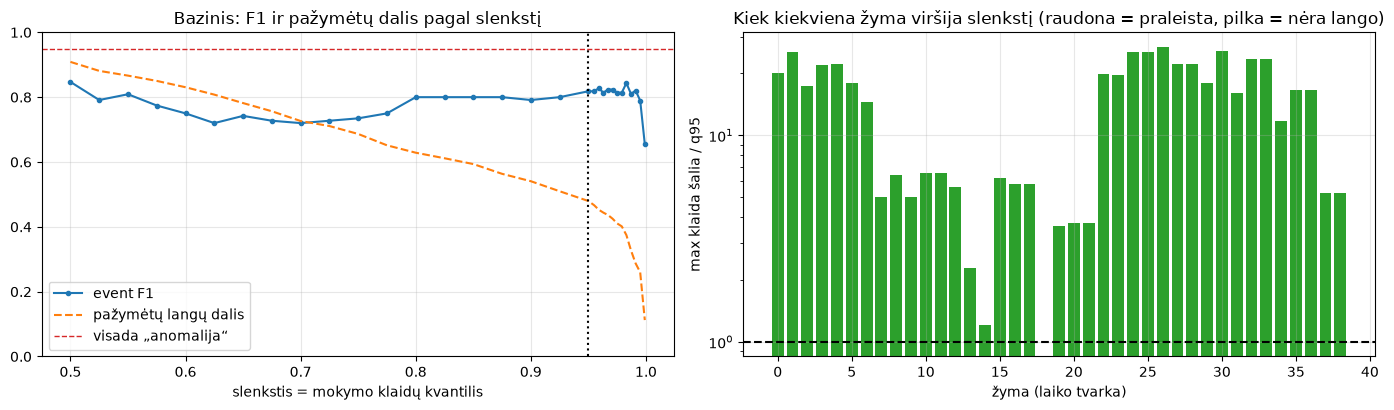

In [6]:
r0 = RUNS["Baseline"][0]
f = r0["s_te"] > r0["q95"]
rng = np.random.default_rng(0)
rand_f1 = np.mean([event_scores_fast(np.isin(np.arange(len(f)), rng.choice(len(f), f.sum(), replace=False)), MATCH)["f1"] for _ in range(300)])
print(f"Bazinis (seed {r0['seed']}), q95 = {r0['q95']:.4f}")
print(f"  pažymėta testo langų: {f.sum()} / {len(f)} ({f.mean():.0%})")
print(f"  event F1: modelis {r0['f1']:.3f} | visada „anomalija“ {ALL_F1:.3f} | atsitiktinis su tiek pat pažymėtų {rand_f1:.3f}")
print(f"  AUROC {r0['auroc']:.3f}, AUPRC {r0['auprc']:.3f} (atsitiktinis AUPRC lygis {y_win.mean():.2f})")

# per anomaly: the largest error among the windows that touch it, relative to the threshold
rows = []
for k, a in enumerate(ANOM):
    w = NEAR[k]
    mx = r0["s_te"][w].max() if w.any() else np.nan
    rows.append(dict(anomaly=a, windows=int(w.sum()), max_error=mx, ratio_to_q95=mx / r0["q95"], detected=bool((w & f).any())))
per_anom = pd.DataFrame(rows)
unreach = per_anom.windows == 0
print(f"\nAptiktos žymos: {per_anom.detected.sum()} / {len(ANOM)}; be nė vieno tinkamo lango (jokiu modeliu nepasiekiamos): {unreach.sum()}")
print("Praleistos žymos (ratio_to_q95 < 1: joks šalia esantis langas neperšoko slenksčio; NaN: šalia nėra tinkamo lango):")
display(per_anom[~per_anom.detected].round({"max_error": 4, "ratio_to_q95": 3}))
print("Aptiktų žymų santykis max klaida / q95 (mediana, min):",
      f"{per_anom[per_anom.detected].ratio_to_q95.median():.1f}, {per_anom[per_anom.detected].ratio_to_q95.min():.2f}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ax[0].plot(QS, f1_curve(r0["s_tr"], r0["s_te"], QS), "o-", ms=3, label="event F1")
ax[0].plot(QS, [(r0["s_te"] > np.quantile(r0["s_tr"], q)).mean() for q in QS], "--", label="pažymėtų langų dalis")
ax[0].axvline(0.95, color="k", ls=":"); ax[0].axhline(ALL_F1, color="tab:red", ls="--", lw=1, label="visada „anomalija“")
ax[0].set(xlabel="slenkstis = mokymo klaidų kvantilis", ylim=(0, 1), title="Bazinis: F1 ir pažymėtų dalis pagal slenkstį"); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].bar(np.arange(len(per_anom)), per_anom.ratio_to_q95.fillna(0), color=np.where(per_anom.detected, "tab:green", np.where(per_anom.windows == 0, "0.7", "tab:red")))
ax[1].axhline(1, color="k", ls="--"); ax[1].set_yscale("log")
ax[1].set(xlabel="žyma (laiko tvarka)", ylabel="max klaida šalia / q95", title="Kiek kiekviena žyma viršija slenkstį (raudona = praleista, pilka = nėra lango)"); ax[1].grid(alpha=0.3)
plt.tight_layout(); save_fig(fig, "attention_v3_baseline_metric_check.png"); plt.show()

## 5A. Self-attention (multi-head) koduotojo išvestyje

**Kas pakeista.** GRU koduotojo būsenos `H` (10 × 16) praleidžiamos per `nn.MultiheadAttention(16, 4 galvos)`, kur kiekviena lango vieta „žiūri“ į kitas. Pridedamas liekamasis ryšys ir LayerNorm (`H + attn(H)`), tada vidurkis per laiką vietoje `h[-1]`. Dekoderis toks pat.

Skirtumai nuo v2: be dropout (v2 turėjo 0,1, todėl mokymas ir vertinimas elgėsi skirtingai) ir su liekamuoju ryšiu, kad dėmesys tik *papildytų* GRU būsenas, o ne jas pakeistų.

In [7]:
class SeqAE_SelfAttn(AEBase):
    def __init__(self, n, hidden=16, latent=8, heads=4):
        super().__init__()
        self.enc = nn.GRU(n, hidden, batch_first=True)
        self.attn = nn.MultiheadAttention(hidden, heads, batch_first=True)      # dropout 0
        self.norm = nn.LayerNorm(hidden)
        self.to_z = nn.Linear(hidden, latent)
        self.from_z, self.dec, self.out = nn.Linear(latent, hidden), nn.GRU(hidden, hidden, batch_first=True), nn.Linear(hidden, n)
    def forward(self, x):
        H, _ = self.enc(x)
        a, _ = self.attn(H, H, H, need_weights=False)
        return self.decode(self.to_z(self.norm(H + a).mean(1)), x.shape[1])
    def attn_weights(self, x):          # how much each window position is attended to (mean over queries and heads)
        H, _ = self.enc(x)
        _, w = self.attn(H, H, H, need_weights=True, average_attn_weights=True)
        return w.mean(1)

run_variant("A: self-attention (MHA)", lambda: SeqAE_SelfAttn(N_FEAT, HIDDEN, LATENT, heads=4), slug="A_selfattn")

[A: self-attention (MHA)] seed 0
    epoch   1/60  loss 0.42716     5.1s
    epoch  10/60  loss 0.02381    50.7s
    epoch  20/60  loss 0.02273   100.5s
    epoch  30/60  loss 0.02227   144.4s
    epoch  40/60  loss 0.02202   165.3s
    epoch  50/60  loss 0.02153   185.1s
    epoch  60/60  loss 0.02159   222.5s
  -> AUROC 0.8576  AUPRC 0.8540 | event q95 P=0.735 R=0.923 F1=0.818 (TP 36, FP 13) | flagged 48.9% | 222s
[A: self-attention (MHA)] seed 1
    epoch   1/60  loss 0.40067     5.9s
    epoch  10/60  loss 0.02381    54.0s
    epoch  20/60  loss 0.02261   103.9s
    epoch  30/60  loss 0.02222   154.0s
    epoch  40/60  loss 0.02210   205.2s
    epoch  50/60  loss 0.02195   256.8s
    epoch  60/60  loss 0.02292   279.6s
  -> AUROC 0.8458  AUPRC 0.8398 | event q95 P=0.735 R=0.923 F1=0.818 (TP 36, FP 13) | flagged 47.1% | 280s
[A: self-attention (MHA)] seed 2
    epoch   1/60  loss 0.40576     2.1s
    epoch  10/60  loss 0.02402    20.2s
    epoch  20/60  loss 0.02284    40.9s
    epo

[{'seed': 0,
  'model': SeqAE_SelfAttn(
    (enc): GRU(6, 16, batch_first=True)
    (attn): MultiheadAttention(
      (out_proj): NonDynamicallyQuantizableLinear(in_features=16, out_features=16, bias=True)
    )
    (norm): LayerNorm((16,), eps=1e-05, elementwise_affine=True, bias=True)
    (to_z): Linear(in_features=16, out_features=8, bias=True)
    (from_z): Linear(in_features=8, out_features=16, bias=True)
    (dec): GRU(16, 16, batch_first=True)
    (out): Linear(in_features=16, out_features=6, bias=True)
  ),
  'hist': [0.4271580237932826,
   0.12684050131076086,
   0.056319653341121184,
   0.03577131309206439,
   0.029314364839335572,
   0.026706329065287825,
   0.025511702970166278,
   0.024575049508757718,
   0.024155934780435744,
   0.023812396357559704,
   0.02358540761567011,
   0.023398318402199813,
   0.0232793919380984,
   0.023155420466440816,
   0.023091556807674184,
   0.02295893375976037,
   0.022886929957457648,
   0.022820965259902144,
   0.022770118041476595,
   0

A: self-attention (MHA)  vs  Baseline   (3 seed: [0, 1, 2]; vidurkis ± st. nuokrypis tarp seed)


,Baseline,A: self-attention (MHA),Δ (variantas − bazinis)
AUROC (slenksčiui nejautrus) ↑,0.8477 ± 0.0027,0.8494 ± 0.0071,0.0017 ± 0.0077
AUPRC ↑,0.8423 ± 0.0033,0.8441 ± 0.0086,0.0018 ± 0.0102
Event F1 @ q95 (straipsnio) ↑,0.818 ± 0.000,0.815 ± 0.005,-0.003 ± 0.005
Event precision @ q95,0.735 ± 0.000,0.730 ± 0.008,-0.005 ± 0.008
Event recall @ q95,0.923 ± 0.000,0.923 ± 0.000,0.000 ± 0.000
TP (iš 39),36.0 ± 0.0,36.0 ± 0.0,0.0 ± 0.0
FP (serijos),13.0 ± 0.0,13.3 ± 0.6,0.3 ± 0.6
Event F1 @ q99,0.831 ± 0.000,0.828 ± 0.006,-0.004 ± 0.006
"Pažymėta testo langų @ q95, %",47.8 ± 0.5,47.6 ± 1.2,-0.2 ± 1.1
Galutinė mokymo MSE ↓,0.02255 ± 0.00099,0.02216 ± 0.00068,-0.00039 ± 0.00038


ΔAUROC = +0.0017 (bazinio AUROC sklaida tarp seed 0.0027) → skirtumas **seed'ų triukšmo ribose**: negalima teigti, kad šis dėmesys padeda ar kenkia.
Event F1 @ q95: 0.818 → 0.815. Abu modeliai pažymi ~48% / 48% langų, todėl F1 mažai jautrus (visada „anomalija“ = 0.947).
[saved] attention_v3_A_selfattn_vs_baseline.png


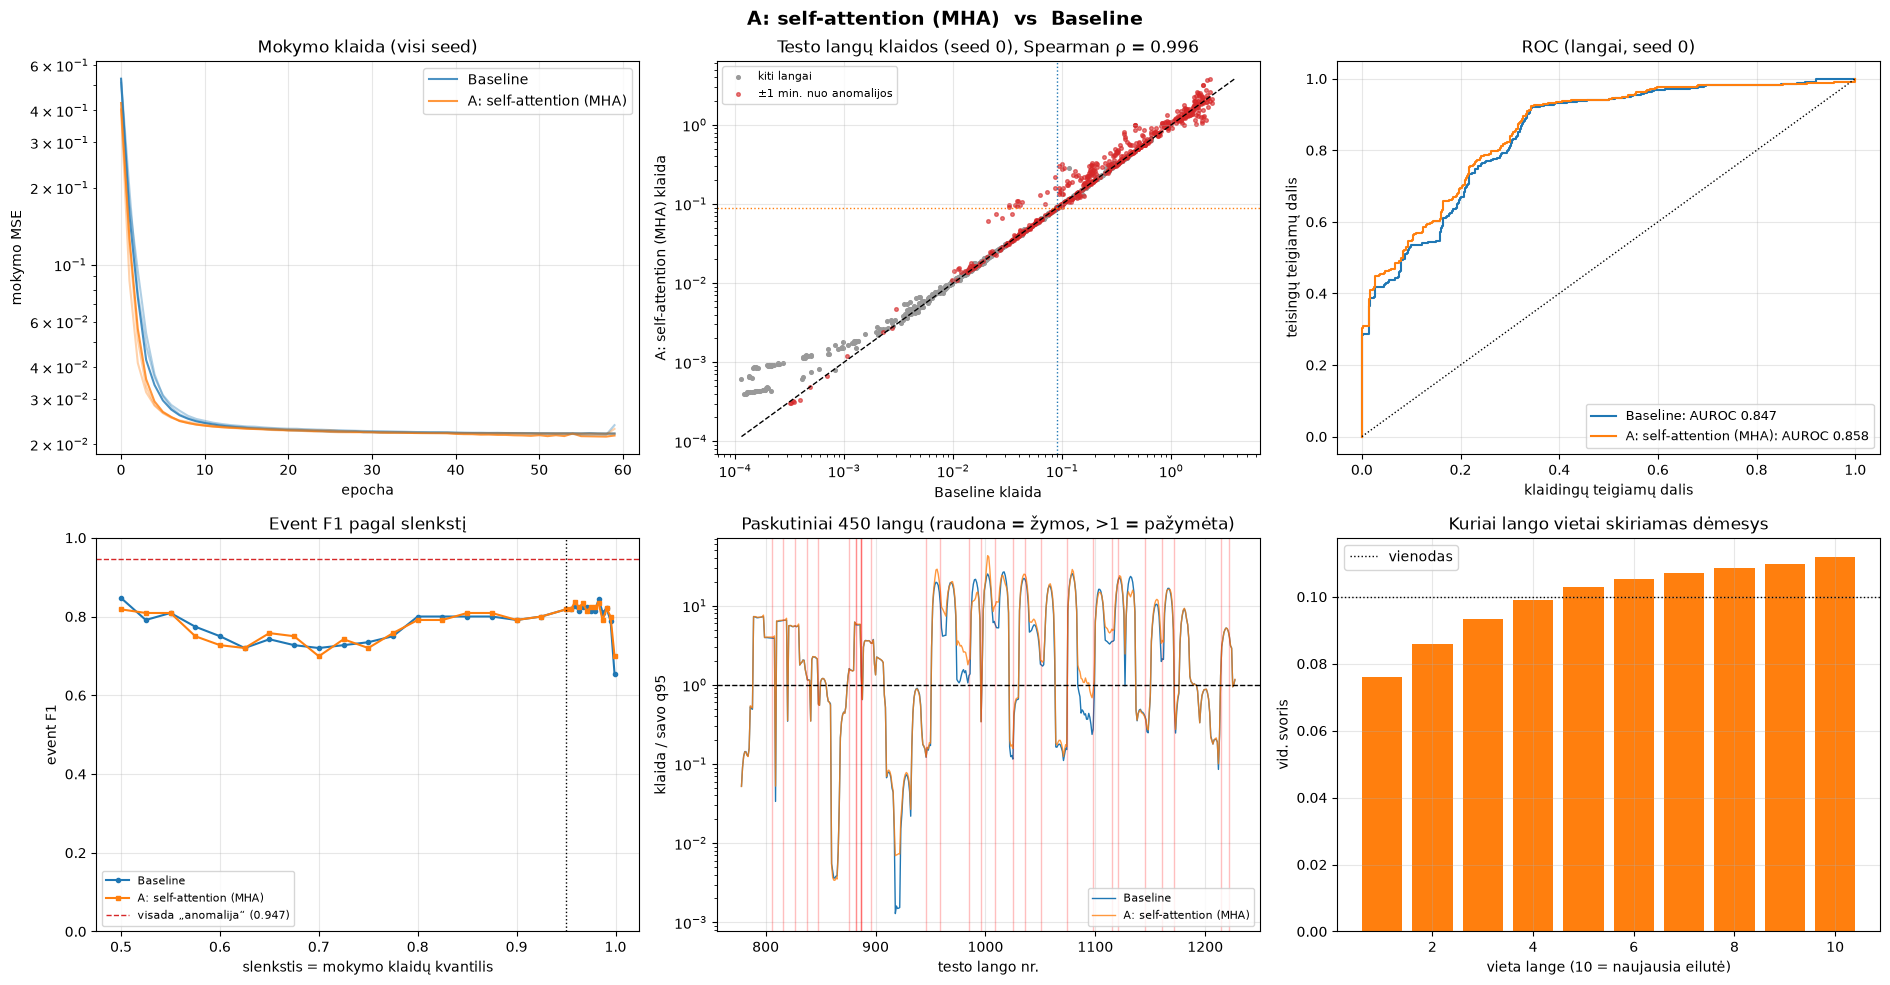

In [8]:
# A prieš bazinį (1 prieš 1)
_ = compare_with_baseline("A: self-attention (MHA)")

## 5B. Additive (Bahdanau) dėmesio pooling

**Kas pakeista.** Kiekvienai lango vietai t mažas tinklas suskaičiuoja balą `v·tanh(W h_t)`, softmax paverčia jį svoriu α_t, o kontekstas yra `Σ α_t h_t`. Jis eina į latentą vietoje `h[-1]`. Modelis pats išmoksta, kurios lango vietos svarbiausios atkūrimui. Grafike (f) matysite, ar svoriai susikoncentruoja (pavyzdžiui, prie naujausių eilučių) ar lieka vienodi.

In [9]:
class SeqAE_AdditivePool(AEBase):
    def __init__(self, n, hidden=16, latent=8):
        super().__init__()
        self.enc = nn.GRU(n, hidden, batch_first=True)
        self.score = nn.Sequential(nn.Linear(hidden, hidden), nn.Tanh(), nn.Linear(hidden, 1, bias=False))
        self.to_z = nn.Linear(hidden, latent)
        self.from_z, self.dec, self.out = nn.Linear(latent, hidden), nn.GRU(hidden, hidden, batch_first=True), nn.Linear(hidden, n)
    def _weights(self, H):
        return torch.softmax(self.score(H).squeeze(-1), dim=1)                 # (B, L)
    def forward(self, x):
        H, _ = self.enc(x)
        c = (self._weights(H).unsqueeze(-1) * H).sum(1)
        return self.decode(self.to_z(c), x.shape[1])
    def attn_weights(self, x):
        H, _ = self.enc(x)
        return self._weights(H)

run_variant("B: additive pooling", lambda: SeqAE_AdditivePool(N_FEAT, HIDDEN, LATENT), slug="B_additive")

[B: additive pooling] seed 0
    epoch   1/60  loss 0.55873     4.3s
    epoch  10/60  loss 0.02512    42.3s
    epoch  20/60  loss 0.02265    85.3s
    epoch  30/60  loss 0.02218   128.0s
    epoch  40/60  loss 0.02203   170.5s
    epoch  50/60  loss 0.02191   209.1s
    epoch  60/60  loss 0.02165   253.4s
  -> AUROC 0.8514  AUPRC 0.8459 | event q95 P=0.735 R=0.923 F1=0.818 (TP 36, FP 13) | flagged 48.3% | 253s
[B: additive pooling] seed 1
    epoch   1/60  loss 0.57003     4.3s
    epoch  10/60  loss 0.02517    43.3s
    epoch  20/60  loss 0.02258    86.7s
    epoch  30/60  loss 0.02219   130.1s
    epoch  40/60  loss 0.02207   174.2s
    epoch  50/60  loss 0.02197   217.0s
    epoch  60/60  loss 0.02213   259.4s
  -> AUROC 0.8488  AUPRC 0.8439 | event q95 P=0.720 R=0.923 F1=0.809 (TP 36, FP 14) | flagged 47.2% | 259s
[B: additive pooling] seed 2
    epoch   1/60  loss 0.47597     4.4s
    epoch  10/60  loss 0.02475    42.8s
    epoch  20/60  loss 0.02273    85.4s
    epoch  30/60  l

[{'seed': 0,
  'model': SeqAE_AdditivePool(
    (enc): GRU(6, 16, batch_first=True)
    (score): Sequential(
      (0): Linear(in_features=16, out_features=16, bias=True)
      (1): Tanh()
      (2): Linear(in_features=16, out_features=1, bias=False)
    )
    (to_z): Linear(in_features=16, out_features=8, bias=True)
    (from_z): Linear(in_features=8, out_features=16, bias=True)
    (dec): GRU(16, 16, batch_first=True)
    (out): Linear(in_features=16, out_features=6, bias=True)
  ),
  'hist': [0.5587316595485442,
   0.1376862040844164,
   0.06984351520474538,
   0.043768279596938416,
   0.034179345839038804,
   0.03019346431476973,
   0.028086260388502256,
   0.02673096458976193,
   0.025816480100678937,
   0.02512213840780062,
   0.02460411927251455,
   0.024162392997134106,
   0.02378307753066729,
   0.023544964905704204,
   0.023306561615239918,
   0.023120033970390468,
   0.022971658402182495,
   0.022840707322488996,
   0.022736306818246864,
   0.02264915124721786,
   0.02256689

B: additive pooling  vs  Baseline   (3 seed: [0, 1, 2]; vidurkis ± st. nuokrypis tarp seed)


,Baseline,B: additive pooling,Δ (variantas − bazinis)
AUROC (slenksčiui nejautrus) ↑,0.8477 ± 0.0027,0.8463 ± 0.0067,-0.0014 ± 0.0053
AUPRC ↑,0.8423 ± 0.0033,0.8403 ± 0.0080,-0.0020 ± 0.0070
Event F1 @ q95 (straipsnio) ↑,0.818 ± 0.000,0.812 ± 0.005,-0.006 ± 0.005
Event precision @ q95,0.735 ± 0.000,0.725 ± 0.008,-0.010 ± 0.008
Event recall @ q95,0.923 ± 0.000,0.923 ± 0.000,0.000 ± 0.000
TP (iš 39),36.0 ± 0.0,36.0 ± 0.0,0.0 ± 0.0
FP (serijos),13.0 ± 0.0,13.7 ± 0.6,0.7 ± 0.6
Event F1 @ q99,0.831 ± 0.000,0.831 ± 0.000,0.000 ± 0.000
"Pažymėta testo langų @ q95, %",47.8 ± 0.5,47.3 ± 1.0,-0.5 ± 0.8
Galutinė mokymo MSE ↓,0.02255 ± 0.00099,0.02190 ± 0.00024,-0.00065 ± 0.00081


ΔAUROC = -0.0014 (bazinio AUROC sklaida tarp seed 0.0027) → skirtumas **seed'ų triukšmo ribose**: negalima teigti, kad šis dėmesys padeda ar kenkia.
Event F1 @ q95: 0.818 → 0.812. Abu modeliai pažymi ~48% / 47% langų, todėl F1 mažai jautrus (visada „anomalija“ = 0.947).
[saved] attention_v3_B_additive_vs_baseline.png


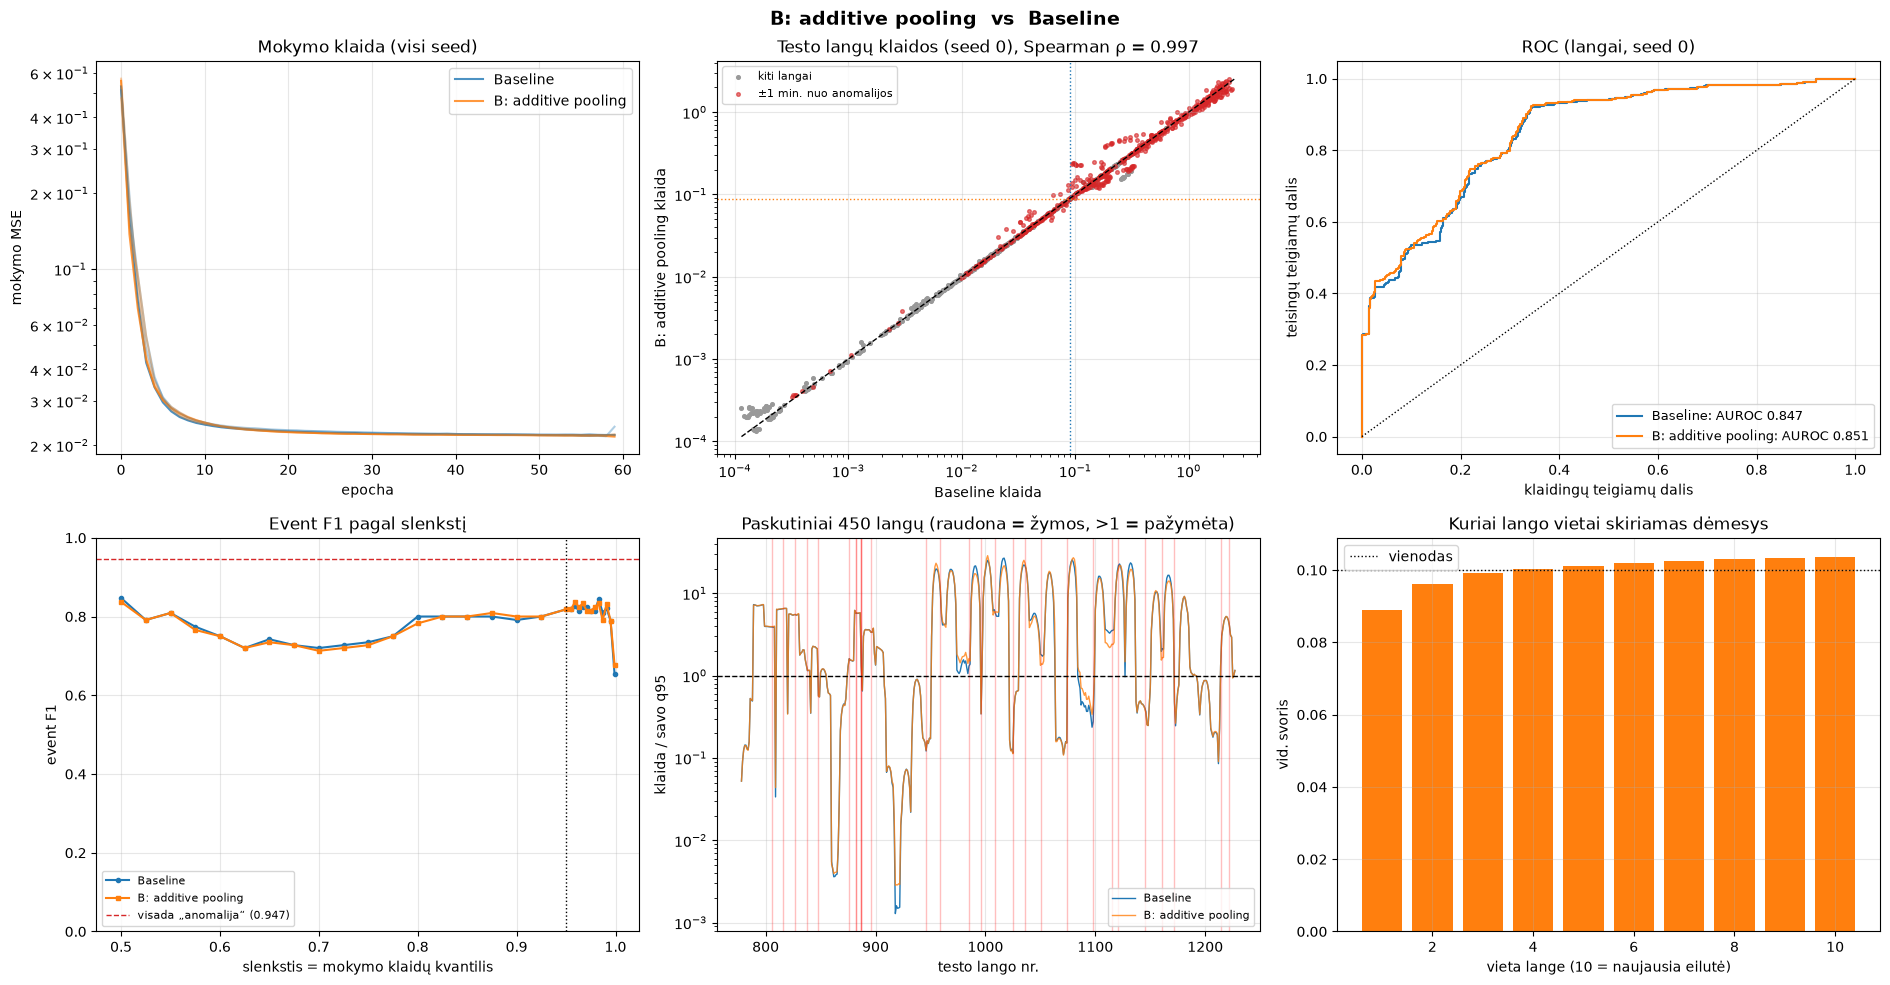

In [10]:
# B prieš bazinį (1 prieš 1)
_ = compare_with_baseline("B: additive pooling")

## 5C. Paskutinė būsena kaip užklausa + sujungimas su `h[-1]`

**Kas pakeista.** Paskutinė GRU būsena `h[-1]` (tai, ką naudoja bazinis) tampa užklausa: `α = softmax(H · W h[-1] / √16)`, o kontekstas yra `Σ α_t h_t`. Svarbu: latentas gauna **abu** `[h[-1], kontekstas]` (32 → 8). Taip modelis nepraranda nieko, ką turi bazinis, o dėmesys yra tik priedas. v2 versijoje buvo naudojamas tik kontekstas.

In [11]:
class SeqAE_LastQueryConcat(AEBase):
    def __init__(self, n, hidden=16, latent=8):
        super().__init__()
        self.enc = nn.GRU(n, hidden, batch_first=True)
        self.query = nn.Linear(hidden, hidden, bias=False)
        self.to_z = nn.Linear(2 * hidden, latent)
        self.from_z, self.dec, self.out = nn.Linear(latent, hidden), nn.GRU(hidden, hidden, batch_first=True), nn.Linear(hidden, n)
        self.hidden = hidden
    def _attend(self, H):
        q = self.query(H[:, -1])                                               # last state asks the question
        w = torch.softmax((H @ q.unsqueeze(-1)).squeeze(-1) / self.hidden ** 0.5, dim=1)
        return (w.unsqueeze(-1) * H).sum(1), w
    def forward(self, x):
        H, _ = self.enc(x)
        c, _ = self._attend(H)
        return self.decode(self.to_z(torch.cat([H[:, -1], c], dim=-1)), x.shape[1])
    def attn_weights(self, x):
        H, _ = self.enc(x)
        return self._attend(H)[1]

run_variant("C: last-state query + concat", lambda: SeqAE_LastQueryConcat(N_FEAT, HIDDEN, LATENT), slug="C_lastquery_concat")

[C: last-state query + concat] seed 0
    epoch   1/60  loss 0.49693     4.1s
    epoch  10/60  loss 0.02429    40.8s
    epoch  20/60  loss 0.02255    61.1s
    epoch  30/60  loss 0.02216    78.7s
    epoch  40/60  loss 0.02201    96.2s
    epoch  50/60  loss 0.02184   114.0s
    epoch  60/60  loss 0.02143   131.9s
  -> AUROC 0.8497  AUPRC 0.8431 | event q95 P=0.735 R=0.923 F1=0.818 (TP 36, FP 13) | flagged 47.1% | 132s
[C: last-state query + concat] seed 1
    epoch   1/60  loss 0.50617     1.8s
    epoch  10/60  loss 0.02401    17.6s
    epoch  20/60  loss 0.02255    49.9s
    epoch  30/60  loss 0.02219    93.5s
    epoch  40/60  loss 0.02205   142.1s
    epoch  50/60  loss 0.02196   187.9s
    epoch  60/60  loss 0.02203   227.2s
  -> AUROC 0.8449  AUPRC 0.8389 | event q95 P=0.735 R=0.923 F1=0.818 (TP 36, FP 13) | flagged 47.1% | 227s
[C: last-state query + concat] seed 2
    epoch   1/60  loss 0.49878     4.4s
    epoch  10/60  loss 0.02505    46.9s
    epoch  20/60  loss 0.02286  

[{'seed': 0,
  'model': SeqAE_LastQueryConcat(
    (enc): GRU(6, 16, batch_first=True)
    (query): Linear(in_features=16, out_features=16, bias=False)
    (to_z): Linear(in_features=32, out_features=8, bias=True)
    (from_z): Linear(in_features=8, out_features=16, bias=True)
    (dec): GRU(16, 16, batch_first=True)
    (out): Linear(in_features=16, out_features=6, bias=True)
  ),
  'hist': [0.4969309649967162,
   0.15657194533663743,
   0.07474956229677597,
   0.04379879565009855,
   0.033680530908661105,
   0.02913697150313172,
   0.026922949225093473,
   0.025581002396438377,
   0.024822729299285366,
   0.02429254529119006,
   0.02391622148049214,
   0.023633502910581538,
   0.02339528465328789,
   0.023189524952284005,
   0.023050213572228768,
   0.022918073027261288,
   0.022798095329748694,
   0.022708582161510657,
   0.022612130088347743,
   0.022551145755724856,
   0.022494735667754857,
   0.022448471173648055,
   0.022439866274127064,
   0.022346669627135912,
   0.02232279370

C: last-state query + concat  vs  Baseline   (3 seed: [0, 1, 2]; vidurkis ± st. nuokrypis tarp seed)


,Baseline,C: last-state query + concat,Δ (variantas − bazinis)
AUROC (slenksčiui nejautrus) ↑,0.8477 ± 0.0027,0.8482 ± 0.0028,0.0005 ± 0.0054
AUPRC ↑,0.8423 ± 0.0033,0.8426 ± 0.0034,0.0003 ± 0.0067
Event F1 @ q95 (straipsnio) ↑,0.818 ± 0.000,0.818 ± 0.000,0.000 ± 0.000
Event precision @ q95,0.735 ± 0.000,0.735 ± 0.000,0.000 ± 0.000
Event recall @ q95,0.923 ± 0.000,0.923 ± 0.000,0.000 ± 0.000
TP (iš 39),36.0 ± 0.0,36.0 ± 0.0,0.0 ± 0.0
FP (serijos),13.0 ± 0.0,13.0 ± 0.0,0.0 ± 0.0
Event F1 @ q99,0.831 ± 0.000,0.828 ± 0.006,-0.004 ± 0.006
"Pažymėta testo langų @ q95, %",47.8 ± 0.5,47.4 ± 0.4,-0.5 ± 1.0
Galutinė mokymo MSE ↓,0.02255 ± 0.00099,0.02169 ± 0.00031,-0.00086 ± 0.00070


ΔAUROC = +0.0005 (bazinio AUROC sklaida tarp seed 0.0027) → skirtumas **seed'ų triukšmo ribose**: negalima teigti, kad šis dėmesys padeda ar kenkia.
Event F1 @ q95: 0.818 → 0.818. Abu modeliai pažymi ~48% / 47% langų, todėl F1 mažai jautrus (visada „anomalija“ = 0.947).
[saved] attention_v3_C_lastquery_concat_vs_baseline.png


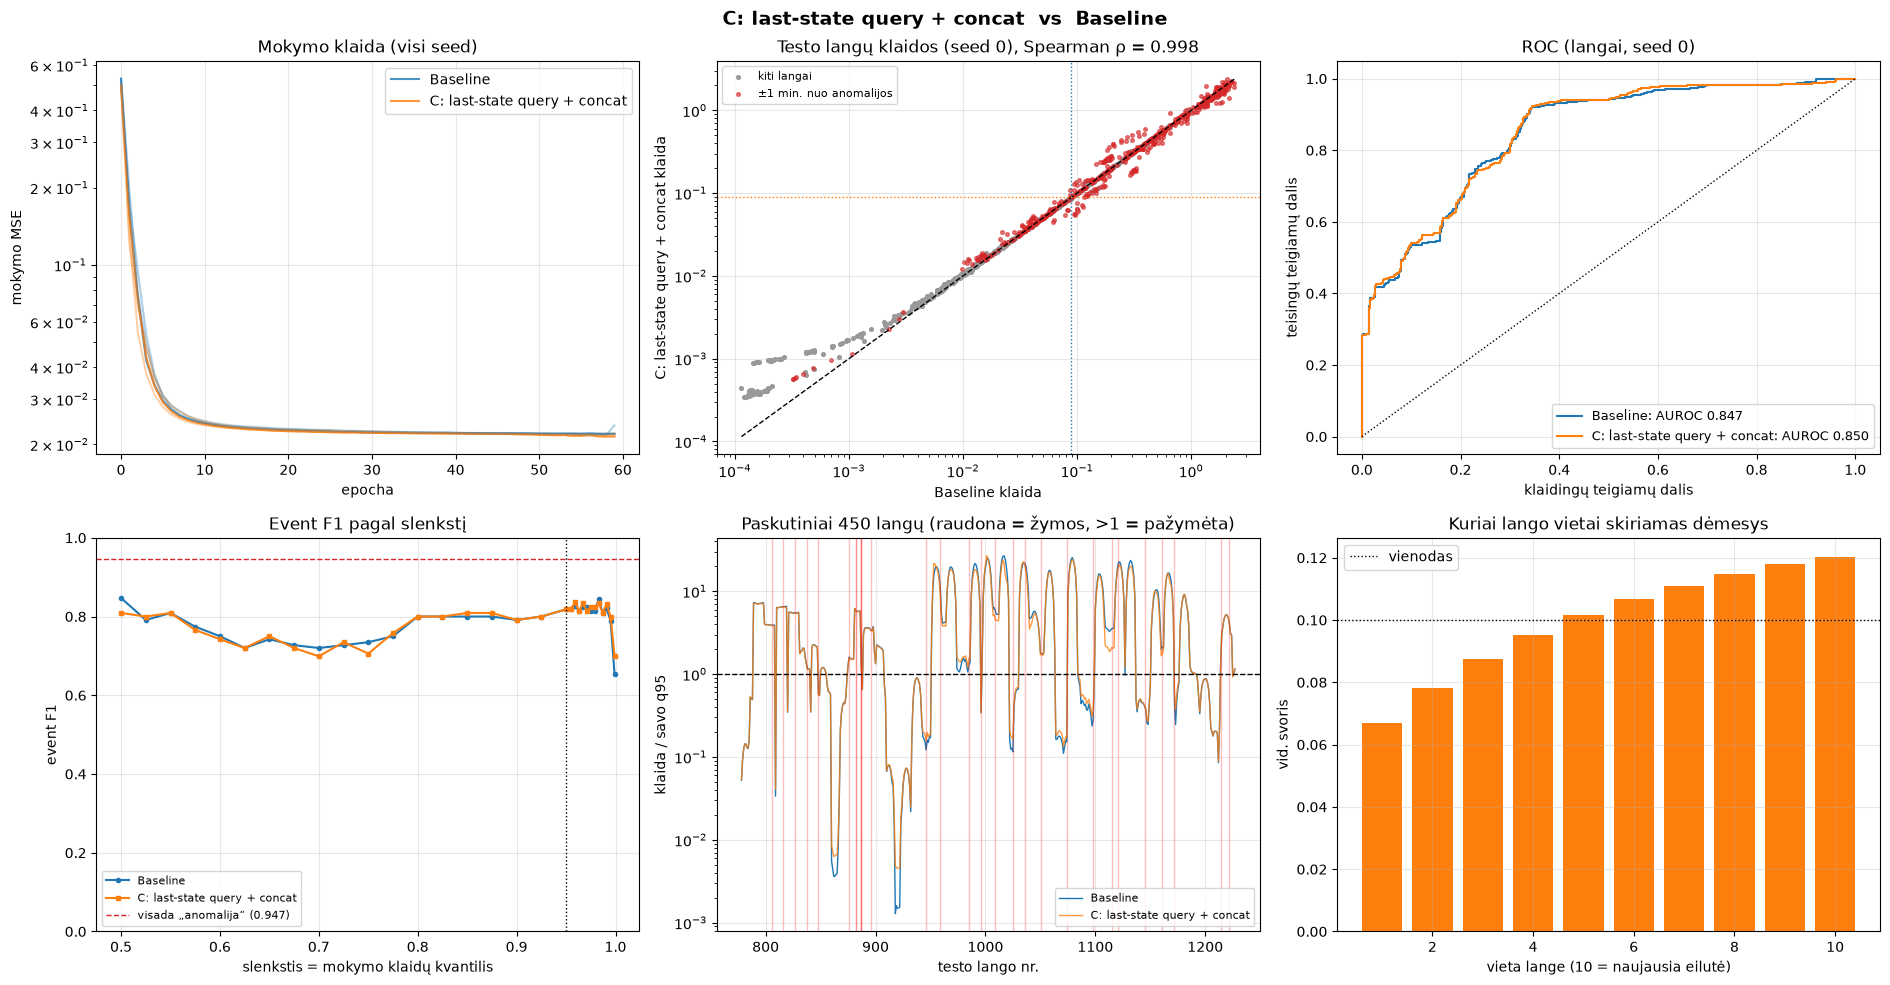

In [12]:
# C prieš bazinį (1 prieš 1)
_ = compare_with_baseline("C: last-state query + concat")

## 5D. Jutiklių (stulpelių) dėmesys

**Kas pakeista.** Kiekviename lango žingsnyje mažas tinklas iš 6 reikšmių suskaičiuoja softmax svorius 6 stulpeliams. Įvestis padauginama iš `6 · svoris` (vienodi svoriai = nieko nepakeista), ir tik tada eina į tą patį GRU-AE. Atkuriama **originali** įvestis. Tai kitokio tipo dėmesys: ne „kur lange“, o „kuris jutiklis“. Grafike (f) matysite, ar modelis labiau remiasi akselerometru ar magnetometru (ataskaitoje: gravitacijos ašies pokytis matomas ties 26 iš 39 žymų).

In [13]:
class SeqAE_FeatureAttn(AEBase):
    attends_to = "features"
    def __init__(self, n, hidden=16, latent=8):
        super().__init__()
        self.gate = nn.Sequential(nn.Linear(n, hidden), nn.Tanh(), nn.Linear(hidden, n))
        self.enc, self.to_z = nn.GRU(n, hidden, batch_first=True), nn.Linear(hidden, latent)
        self.from_z, self.dec, self.out = nn.Linear(latent, hidden), nn.GRU(hidden, hidden, batch_first=True), nn.Linear(hidden, n)
        self.n = n
    def forward(self, x):
        w = torch.softmax(self.gate(x), dim=-1)                                # (B, L, 6), sums to 1 over sensors
        _, h = self.enc(x * w * self.n)
        return self.decode(self.to_z(h[-1]), x.shape[1])
    def attn_weights(self, x):
        return torch.softmax(self.gate(x), dim=-1).mean(1)                     # (B, 6): mean over the window

run_variant("D: feature (sensor) attention", lambda: SeqAE_FeatureAttn(N_FEAT, HIDDEN, LATENT), slug="D_feature_attn")

[D: feature (sensor) attention] seed 0
    epoch   1/60  loss 0.47809     4.5s
    epoch  10/60  loss 0.02755    45.7s
    epoch  20/60  loss 0.02324    88.0s
    epoch  30/60  loss 0.02261   106.0s
    epoch  40/60  loss 0.02238   123.4s
    epoch  50/60  loss 0.02215   140.5s
    epoch  60/60  loss 0.02193   157.6s
  -> AUROC 0.8499  AUPRC 0.8476 | event q95 P=0.720 R=0.923 F1=0.809 (TP 36, FP 14) | flagged 47.6% | 158s
[D: feature (sensor) attention] seed 1
    epoch   1/60  loss 0.54786     1.7s
    epoch  10/60  loss 0.02624    17.0s
    epoch  20/60  loss 0.02316    34.6s
    epoch  30/60  loss 0.02262    67.0s
    epoch  40/60  loss 0.02234   110.1s
    epoch  50/60  loss 0.02210   174.8s
    epoch  60/60  loss 0.02206   240.7s
  -> AUROC 0.8457  AUPRC 0.8385 | event q95 P=0.735 R=0.923 F1=0.818 (TP 36, FP 13) | flagged 48.0% | 241s
[D: feature (sensor) attention] seed 2
    epoch   1/60  loss 0.51815     6.4s
    epoch  10/60  loss 0.02479    67.7s
    epoch  20/60  loss 0.0228

[{'seed': 0,
  'model': SeqAE_FeatureAttn(
    (gate): Sequential(
      (0): Linear(in_features=6, out_features=16, bias=True)
      (1): Tanh()
      (2): Linear(in_features=16, out_features=6, bias=True)
    )
    (enc): GRU(6, 16, batch_first=True)
    (to_z): Linear(in_features=16, out_features=8, bias=True)
    (from_z): Linear(in_features=8, out_features=16, bias=True)
    (dec): GRU(16, 16, batch_first=True)
    (out): Linear(in_features=16, out_features=6, bias=True)
  ),
  'hist': [0.4780880913802112,
   0.1540135399024529,
   0.08330322305638535,
   0.05606215403559995,
   0.04531909592115809,
   0.03967346496581446,
   0.036113186313876375,
   0.03307309309802906,
   0.029852578641420643,
   0.027551291240285276,
   0.026313504905950424,
   0.02550189956819161,
   0.024895765502340003,
   0.02447769184692687,
   0.02416269441667602,
   0.02387784981218436,
   0.023665148980866,
   0.023502680705257555,
   0.023358604082566525,
   0.02323965975017321,
   0.02312513860603451,

D: feature (sensor) attention  vs  Baseline   (3 seed: [0, 1, 2]; vidurkis ± st. nuokrypis tarp seed)


,Baseline,D: feature (sensor) attention,Δ (variantas − bazinis)
AUROC (slenksčiui nejautrus) ↑,0.8477 ± 0.0027,0.8502 ± 0.0047,0.0025 ± 0.0073
AUPRC ↑,0.8423 ± 0.0033,0.8465 ± 0.0075,0.0042 ± 0.0107
Event F1 @ q95 (straipsnio) ↑,0.818 ± 0.000,0.815 ± 0.005,-0.003 ± 0.005
Event precision @ q95,0.735 ± 0.000,0.730 ± 0.008,-0.005 ± 0.008
Event recall @ q95,0.923 ± 0.000,0.923 ± 0.000,0.000 ± 0.000
TP (iš 39),36.0 ± 0.0,36.0 ± 0.0,0.0 ± 0.0
FP (serijos),13.0 ± 0.0,13.3 ± 0.6,0.3 ± 0.6
Event F1 @ q99,0.831 ± 0.000,0.831 ± 0.000,0.000 ± 0.000
"Pažymėta testo langų @ q95, %",47.8 ± 0.5,48.0 ± 0.3,0.2 ± 0.8
Galutinė mokymo MSE ↓,0.02255 ± 0.00099,0.02201 ± 0.00007,-0.00054 ± 0.00095


ΔAUROC = +0.0025 (bazinio AUROC sklaida tarp seed 0.0027) → skirtumas **seed'ų triukšmo ribose**: negalima teigti, kad šis dėmesys padeda ar kenkia.
Event F1 @ q95: 0.818 → 0.815. Abu modeliai pažymi ~48% / 48% langų, todėl F1 mažai jautrus (visada „anomalija“ = 0.947).
[saved] attention_v3_D_feature_attn_vs_baseline.png


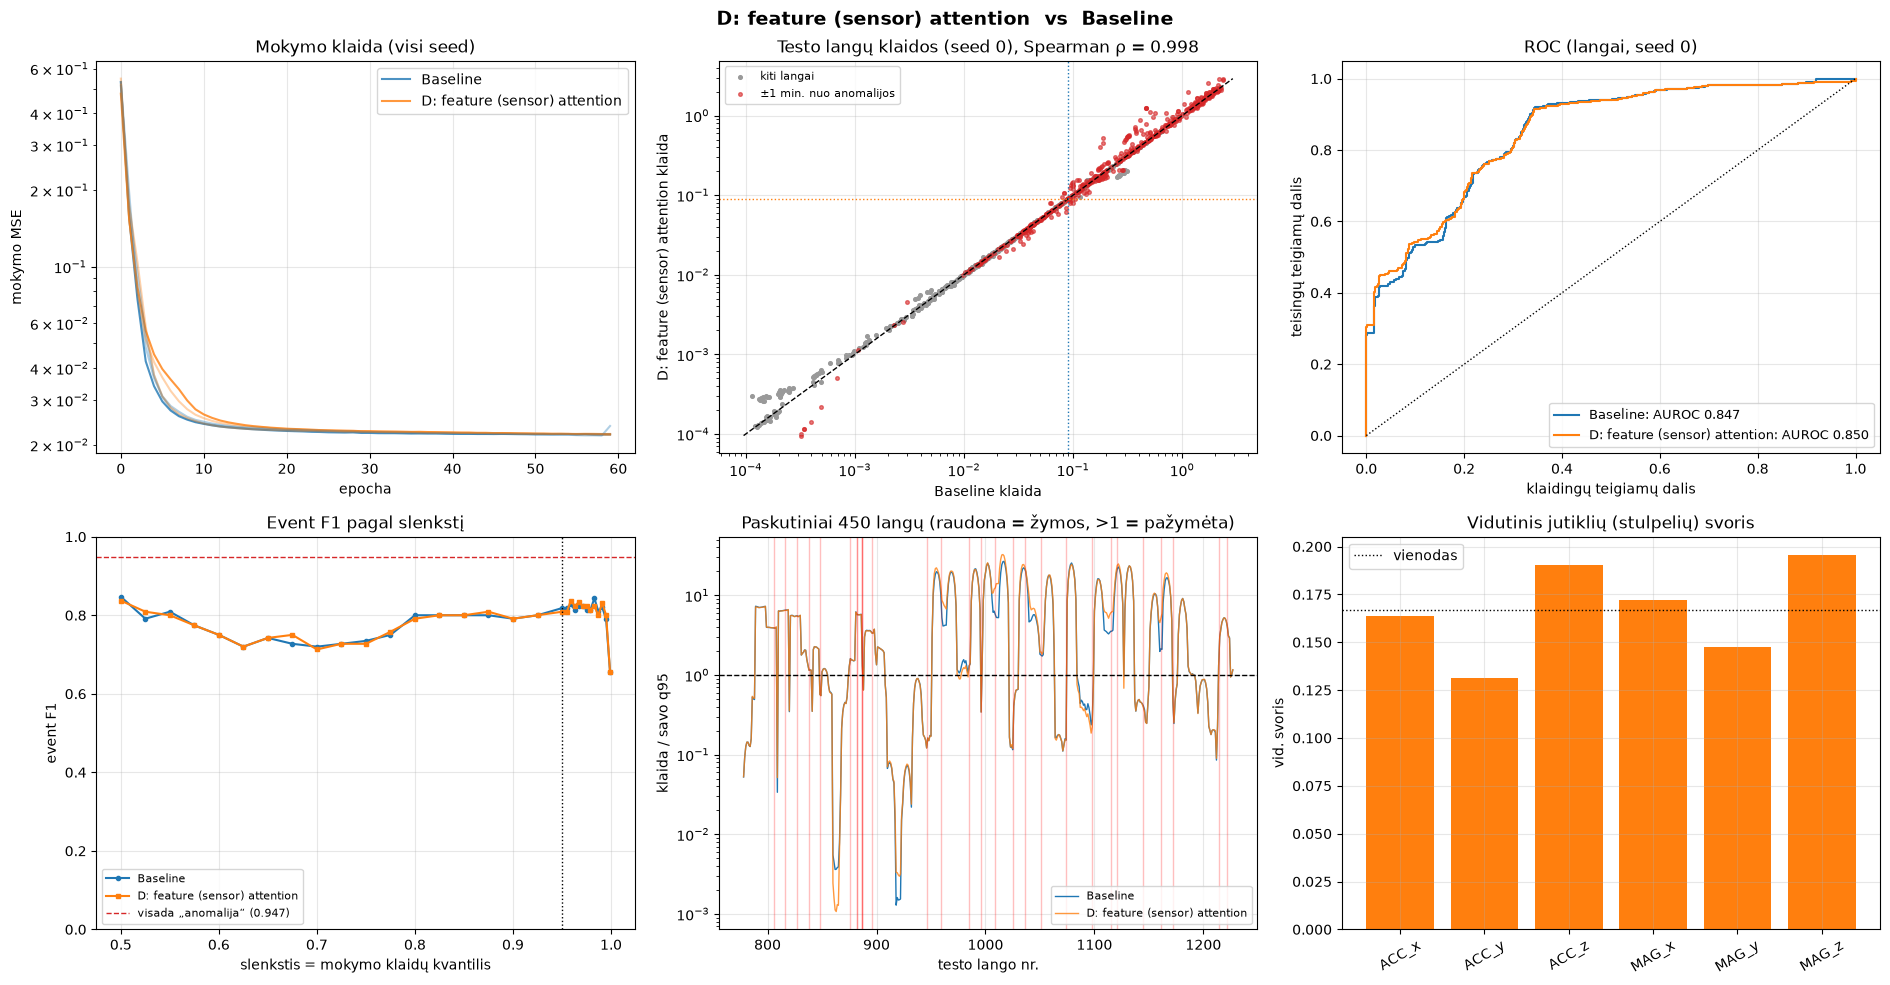

In [14]:
# D prieš bazinį (1 prieš 1)
_ = compare_with_baseline("D: feature (sensor) attention")

## 5E. Dekoderio cross-attention

**Kas pakeista.** Kaip baziniame, dekoderis gauna latentą. Be to, kiekviena dekoderio pozicija per dėmesį tiesiogiai „žiūri“ į visas koduotojo būsenas, o išvestis = `Linear([dekoderio būsena, kontekstas])`.

**Pastaba (svarbu ataskaitai).** Autoenkoderiui tai pavojinga: dekoderis gali *nukopijuoti* informaciją iš koduotojo ir apeiti 8 skaičių „butelio kakliuką“. Tada jis gerai atkuria **ir anomalijas**, ir klaida nustoja jas skirti. v2 notebooke tai jau matėsi: mokymo MSE krito ~6 kartus (q95 0,089 → 0,014), o F1 nukrito iki 0,75. Įtraukiame kaip kontrolinį eksperimentą: jei AUROC krenta, tai patvirtina, kad aptikimas remiasi butelio kakliuku.

In [15]:
class SeqAE_DecoderCross(nn.Module):
    def __init__(self, n, hidden=16, latent=8):
        super().__init__()
        self.enc, self.to_z = nn.GRU(n, hidden, batch_first=True), nn.Linear(hidden, latent)
        self.from_z, self.dec = nn.Linear(latent, hidden), nn.GRU(hidden, hidden, batch_first=True)
        self.query = nn.Linear(hidden, hidden, bias=False)
        self.out = nn.Linear(2 * hidden, n)
        self.hidden = hidden
    def _run(self, x):
        H, h = self.enc(x)
        D, _ = self.dec(self.from_z(self.to_z(h[-1])).unsqueeze(1).repeat(1, x.shape[1], 1))
        w = torch.softmax(self.query(D) @ H.transpose(1, 2) / self.hidden ** 0.5, dim=-1)    # (B, L_dec, L_enc)
        return self.out(torch.cat([D, w @ H], dim=-1)), w
    def forward(self, x):
        return self._run(x)[0]
    def attn_weights(self, x):
        return self._run(x)[1]

run_variant("E: decoder cross-attention", lambda: SeqAE_DecoderCross(N_FEAT, HIDDEN, LATENT), slug="E_decoder_cross")

[E: decoder cross-attention] seed 0
    epoch   1/60  loss 0.44095     5.4s
    epoch  10/60  loss 0.02392    23.0s
    epoch  20/60  loss 0.02234    40.9s
    epoch  30/60  loss 0.02185    58.1s
    epoch  40/60  loss 0.01390    75.1s
    epoch  50/60  loss 0.00856    92.6s
    epoch  60/60  loss 0.00311   116.4s
  -> AUROC 0.8396  AUPRC 0.8044 | event q95 P=0.632 R=0.923 F1=0.750 (TP 36, FP 21) | flagged 47.4% | 116s
[E: decoder cross-attention] seed 1
    epoch   1/60  loss 0.45518     3.5s
    epoch  10/60  loss 0.02345    30.7s
    epoch  20/60  loss 0.02226    69.8s
    epoch  30/60  loss 0.02184   105.9s
    epoch  40/60  loss 0.01457   124.4s
    epoch  50/60  loss 0.01071   145.2s
    epoch  60/60  loss 0.00657   167.2s
  -> AUROC 0.8407  AUPRC 0.8233 | event q95 P=0.692 R=0.923 F1=0.791 (TP 36, FP 16) | flagged 47.4% | 167s
[E: decoder cross-attention] seed 2
    epoch   1/60  loss 0.40915     2.4s
    epoch  10/60  loss 0.02348    25.9s
    epoch  20/60  loss 0.02202    48.0

[{'seed': 0,
  'model': SeqAE_DecoderCross(
    (enc): GRU(6, 16, batch_first=True)
    (to_z): Linear(in_features=16, out_features=8, bias=True)
    (from_z): Linear(in_features=8, out_features=16, bias=True)
    (dec): GRU(16, 16, batch_first=True)
    (query): Linear(in_features=16, out_features=16, bias=False)
    (out): Linear(in_features=32, out_features=6, bias=True)
  ),
  'hist': [0.44095156157771187,
   0.08757780021565131,
   0.040475644951676784,
   0.03252492377925726,
   0.029292792159644,
   0.027287004729342985,
   0.02610330599808704,
   0.02506509145039616,
   0.02441069389070202,
   0.02392100246768971,
   0.023570155025461115,
   0.023265583665282835,
   0.023048770777737496,
   0.02288669611822066,
   0.022745859157136086,
   0.022636771543591745,
   0.022540120345340912,
   0.022456882819827634,
   0.022388617894093098,
   0.02233532334740307,
   0.02228927281848527,
   0.022224138198149564,
   0.02220949380183304,
   0.02214792534748215,
   0.022101015466761926,


E: decoder cross-attention  vs  Baseline   (3 seed: [0, 1, 2]; vidurkis ± st. nuokrypis tarp seed)


,Baseline,E: decoder cross-attention,Δ (variantas − bazinis)
AUROC (slenksčiui nejautrus) ↑,0.8477 ± 0.0027,0.8461 ± 0.0104,-0.0016 ± 0.0126
AUPRC ↑,0.8423 ± 0.0033,0.8164 ± 0.0104,-0.0259 ± 0.0094
Event F1 @ q95 (straipsnio) ↑,0.818 ± 0.000,0.790 ± 0.039,-0.029 ± 0.039
Event precision @ q95,0.735 ± 0.000,0.691 ± 0.059,-0.043 ± 0.059
Event recall @ q95,0.923 ± 0.000,0.923 ± 0.000,0.000 ± 0.000
TP (iš 39),36.0 ± 0.0,36.0 ± 0.0,0.0 ± 0.0
FP (serijos),13.0 ± 0.0,16.3 ± 4.5,3.3 ± 4.5
Event F1 @ q99,0.831 ± 0.000,0.788 ± 0.021,-0.043 ± 0.021
"Pažymėta testo langų @ q95, %",47.8 ± 0.5,46.9 ± 0.9,-1.0 ± 0.5
Galutinė mokymo MSE ↓,0.02255 ± 0.00099,0.00365 ± 0.00268,-0.01890 ± 0.00179


ΔAUROC = -0.0016 (bazinio AUROC sklaida tarp seed 0.0027) → skirtumas **seed'ų triukšmo ribose**: negalima teigti, kad šis dėmesys padeda ar kenkia.
Event F1 @ q95: 0.818 → 0.790. Abu modeliai pažymi ~48% / 47% langų, todėl F1 mažai jautrus (visada „anomalija“ = 0.947).
[saved] attention_v3_E_decoder_cross_vs_baseline.png


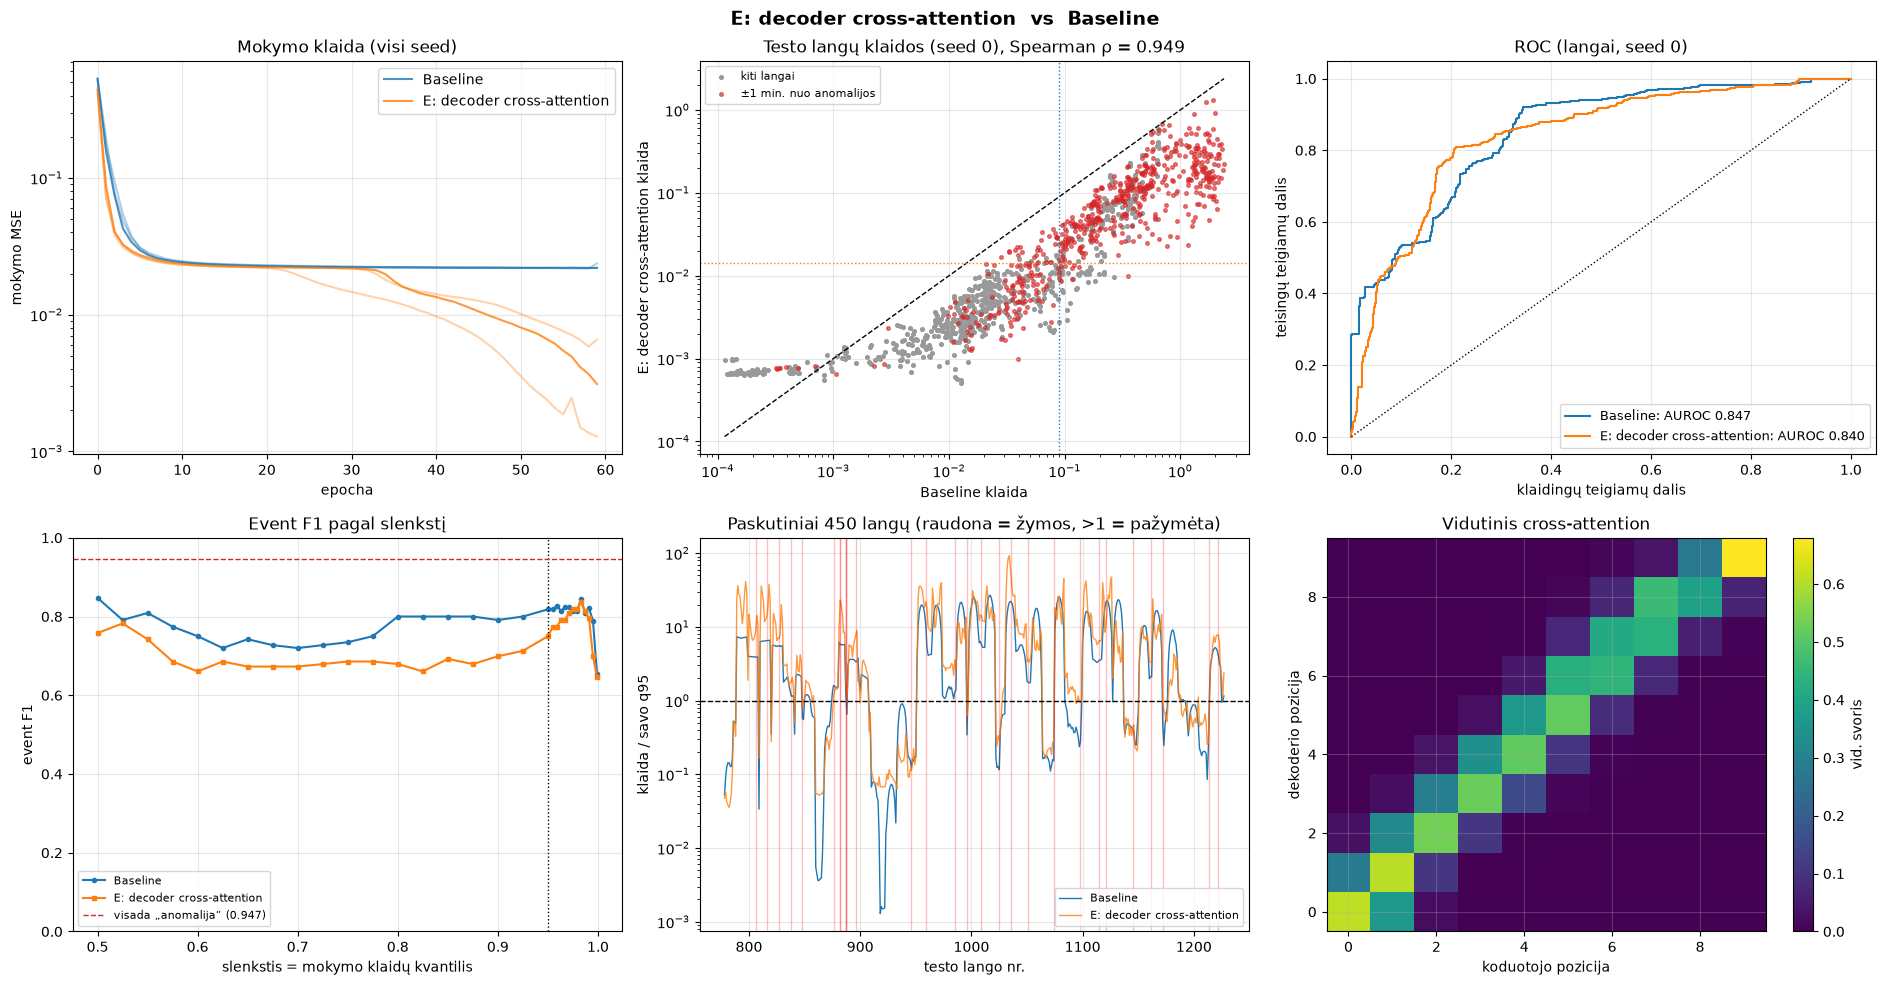

In [16]:
# E prieš bazinį (1 prieš 1)
_ = compare_with_baseline("E: decoder cross-attention")

## 5F. Transformerio koduotojas vietoje GRU

**Kas pakeista.** Koduotojas be rekurencijos: tiesinis įterpinys 6 → 16, išmokti pozicijų įterpiniai, vienas transformerio blokas (4 galvų self-attention + FFN 32, liekamieji ryšiai, LayerNorm, be dropout), tada vidurkis per laiką → latentas. Dekoderis tas pats GRU. Tai atsako į ataskaitos klausimą „kodėl ne transformeris?“: ar dėmesys gali pakeisti GRU koduotoją.

In [17]:
class SeqAE_TransformerEnc(AEBase):
    def __init__(self, n, hidden=16, latent=8, heads=4, L=10):
        super().__init__()
        self.inp = nn.Linear(n, hidden)
        self.pos = nn.Parameter(torch.randn(1, L, hidden) * 0.02)
        self.attn = nn.MultiheadAttention(hidden, heads, batch_first=True)
        self.n1, self.n2 = nn.LayerNorm(hidden), nn.LayerNorm(hidden)
        self.ff = nn.Sequential(nn.Linear(hidden, 2 * hidden), nn.ReLU(), nn.Linear(2 * hidden, hidden))
        self.to_z = nn.Linear(hidden, latent)
        self.from_z, self.dec, self.out = nn.Linear(latent, hidden), nn.GRU(hidden, hidden, batch_first=True), nn.Linear(hidden, n)
    def _encode(self, x):
        E = self.inp(x) + self.pos[:, : x.shape[1]]
        a, w = self.attn(E, E, E, need_weights=True, average_attn_weights=True)
        H = self.n1(E + a)
        return self.n2(H + self.ff(H)), w
    def forward(self, x):
        H, _ = self._encode(x)
        return self.decode(self.to_z(H.mean(1)), x.shape[1])
    def attn_weights(self, x):
        return self._encode(x)[1].mean(1)

run_variant("F: transformer encoder", lambda: SeqAE_TransformerEnc(N_FEAT, HIDDEN, LATENT, heads=4, L=L), slug="F_transformer_enc")

[F: transformer encoder] seed 0
    epoch   1/60  loss 0.44239     3.9s
    epoch  10/60  loss 0.02406    36.7s
    epoch  20/60  loss 0.02292    74.0s
    epoch  30/60  loss 0.02263   111.4s
    epoch  40/60  loss 0.02239   149.0s
    epoch  50/60  loss 0.02216   187.2s
    epoch  60/60  loss 0.02197   224.5s
  -> AUROC 0.8473  AUPRC 0.8425 | event q95 P=0.720 R=0.923 F1=0.809 (TP 36, FP 14) | flagged 47.7% | 225s
[F: transformer encoder] seed 1
    epoch   1/60  loss 0.42862     3.9s
    epoch  10/60  loss 0.02330    28.1s
    epoch  20/60  loss 0.02230    47.0s
    epoch  30/60  loss 0.02209    69.0s
    epoch  40/60  loss 0.02206    87.8s
    epoch  50/60  loss 0.02195   111.6s
    epoch  60/60  loss 0.02650   130.7s
  -> AUROC 0.8513  AUPRC 0.8450 | event q95 P=0.735 R=0.923 F1=0.818 (TP 36, FP 13) | flagged 48.9% | 131s
[F: transformer encoder] seed 2
    epoch   1/60  loss 0.45199     2.3s
    epoch  10/60  loss 0.02448    22.6s
    epoch  20/60  loss 0.02288    43.2s
    epoch 

[{'seed': 0,
  'model': SeqAE_TransformerEnc(
    (inp): Linear(in_features=6, out_features=16, bias=True)
    (attn): MultiheadAttention(
      (out_proj): NonDynamicallyQuantizableLinear(in_features=16, out_features=16, bias=True)
    )
    (n1): LayerNorm((16,), eps=1e-05, elementwise_affine=True, bias=True)
    (n2): LayerNorm((16,), eps=1e-05, elementwise_affine=True, bias=True)
    (ff): Sequential(
      (0): Linear(in_features=16, out_features=32, bias=True)
      (1): ReLU()
      (2): Linear(in_features=32, out_features=16, bias=True)
    )
    (to_z): Linear(in_features=16, out_features=8, bias=True)
    (from_z): Linear(in_features=8, out_features=16, bias=True)
    (dec): GRU(16, 16, batch_first=True)
    (out): Linear(in_features=16, out_features=6, bias=True)
  ),
  'hist': [0.4423924319437441,
   0.11785246077986485,
   0.05399907703990171,
   0.03603472130488341,
   0.02989572937268038,
   0.02726652675237542,
   0.02593439712630899,
   0.024969170412951006,
   0.02443

F: transformer encoder  vs  Baseline   (3 seed: [0, 1, 2]; vidurkis ± st. nuokrypis tarp seed)


,Baseline,F: transformer encoder,Δ (variantas − bazinis)
AUROC (slenksčiui nejautrus) ↑,0.8477 ± 0.0027,0.8479 ± 0.0031,0.0002 ± 0.0005
AUPRC ↑,0.8423 ± 0.0033,0.8427 ± 0.0022,0.0004 ± 0.0014
Event F1 @ q95 (straipsnio) ↑,0.818 ± 0.000,0.815 ± 0.005,-0.003 ± 0.005
Event precision @ q95,0.735 ± 0.000,0.730 ± 0.008,-0.005 ± 0.008
Event recall @ q95,0.923 ± 0.000,0.923 ± 0.000,0.000 ± 0.000
TP (iš 39),36.0 ± 0.0,36.0 ± 0.0,0.0 ± 0.0
FP (serijos),13.0 ± 0.0,13.3 ± 0.6,0.3 ± 0.6
Event F1 @ q99,0.831 ± 0.000,0.831 ± 0.000,0.000 ± 0.000
"Pažymėta testo langų @ q95, %",47.8 ± 0.5,47.1 ± 2.1,-0.7 ± 1.6
Galutinė mokymo MSE ↓,0.02255 ± 0.00099,0.02345 ± 0.00264,0.00090 ± 0.00165


ΔAUROC = +0.0002 (bazinio AUROC sklaida tarp seed 0.0027) → skirtumas **seed'ų triukšmo ribose**: negalima teigti, kad šis dėmesys padeda ar kenkia.
Event F1 @ q95: 0.818 → 0.815. Abu modeliai pažymi ~48% / 47% langų, todėl F1 mažai jautrus (visada „anomalija“ = 0.947).
[saved] attention_v3_F_transformer_enc_vs_baseline.png


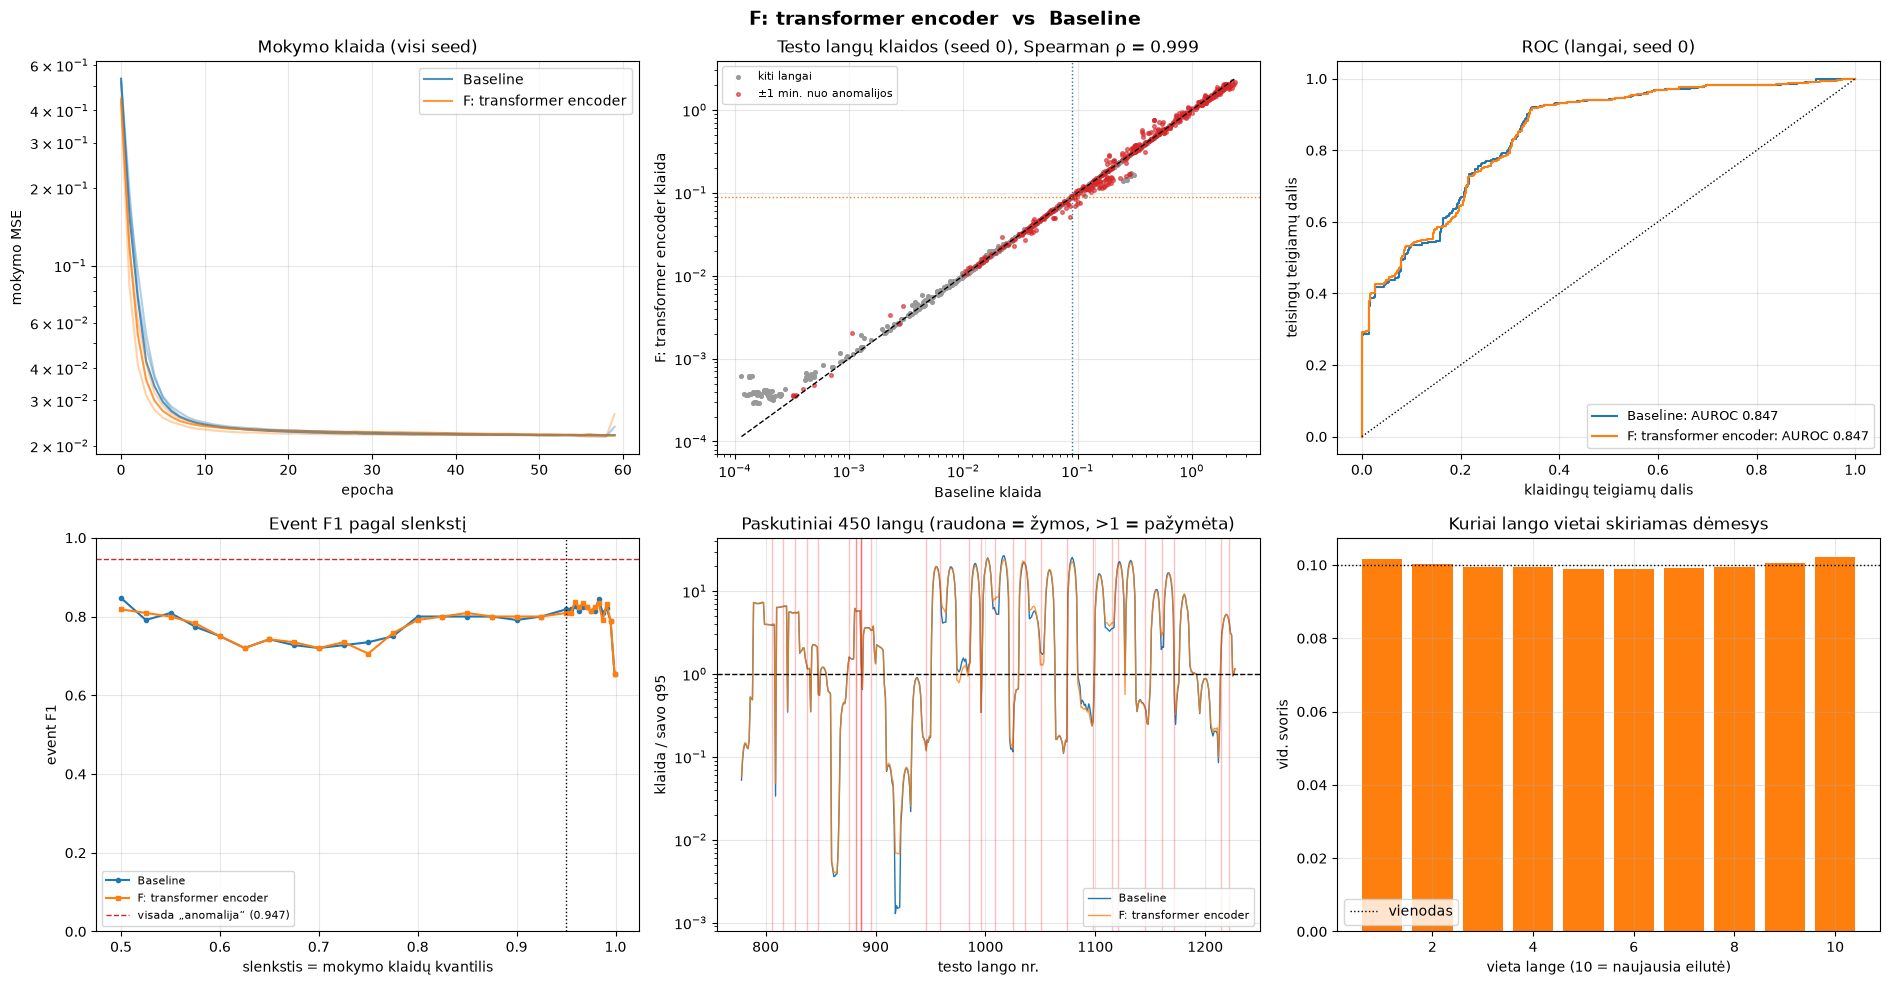

In [18]:
# F prieš bazinį (1 prieš 1)
_ = compare_with_baseline("F: transformer encoder")

## 6. Visų modelių santrauka

Paleiskite po bet kurio skaičiaus variantų: įtraukiami visi, kurie jau apmokyti šiame kernelyje. Lentelė rūšiuojama pagal AUROC. Δ yra skirtumas nuo bazinio, suporuotas pagal seed. Išsaugoma į **naujus** failus `attention_v3_summary.csv` ir `attention_v3_summary.png`.

**Kaip skaityti.** (1) Žiūrėkite į AUROC/AUPRC ir jų Δ, lygindami su bazinio sklaida tarp seed. (2) Event F1 rodo, ar pasiekiame straipsnio lygį, bet beveik nereaguoja į modelio pakeitimus (4 dalis). (3) Visi variantai vertinami tame pačiame testo rinkinyje, todėl tai yra *tyrimas*, ne nepriklausomas modelio pasirinkimas.

,model,AUROC,ΔAUROC,AUPRC,ΔAUPRC,F1@q95,F1@q99,TP,FP,pažymėta %,mokymo MSE,params,s/mod.
0,D: feature (sensor) attention,0.8502 ± 0.0047,0.0025 ± 0.0073,0.8465 ± 0.0075,0.0042 ± 0.0107,0.815 ± 0.005,0.831 ± 0.000,36.0 ± 0.0,13.3 ± 0.6,48.0 ± 0.3,0.02201 ± 0.00007,3380,268 ± 127
1,A: self-attention (MHA),0.8494 ± 0.0071,0.0017 ± 0.0077,0.8441 ± 0.0086,0.0018 ± 0.0102,0.815 ± 0.005,0.828 ± 0.006,36.0 ± 0.0,13.3 ± 0.6,47.6 ± 1.2,0.02216 ± 0.00068,4286,244 ± 31
2,C: last-state query + concat,0.8482 ± 0.0028,0.0005 ± 0.0054,0.8426 ± 0.0034,0.0003 ± 0.0067,0.818 ± 0.000,0.828 ± 0.006,36.0 ± 0.0,13.0 ± 0.0,47.4 ± 0.4,0.02169 ± 0.00031,3550,209 ± 70
3,F: transformer encoder,0.8479 ± 0.0031,0.0002 ± 0.0005,0.8427 ± 0.0022,0.0004 ± 0.0014,0.815 ± 0.005,0.831 ± 0.000,36.0 ± 0.0,13.3 ± 0.6,47.1 ± 2.1,0.02345 ± 0.00264,4510,157 ± 59
4,Baseline,0.8477 ± 0.0027,,0.8423 ± 0.0033,,0.818 ± 0.000,0.831 ± 0.000,36.0 ± 0.0,13.0 ± 0.0,47.8 ± 0.5,0.02255 ± 0.00099,3166,135 ± 44
5,B: additive pooling,0.8463 ± 0.0067,-0.0014 ± 0.0053,0.8403 ± 0.0080,-0.0020 ± 0.0070,0.812 ± 0.005,0.831 ± 0.000,36.0 ± 0.0,13.7 ± 0.6,47.3 ± 1.0,0.02190 ± 0.00024,3454,258 ± 4
6,E: decoder cross-attention,0.8461 ± 0.0104,-0.0016 ± 0.0126,0.8164 ± 0.0104,-0.0259 ± 0.0094,0.790 ± 0.039,0.788 ± 0.021,36.0 ± 0.0,16.3 ± 4.5,46.9 ± 0.9,0.00365 ± 0.00268,3518,157 ± 36


[saved] attention_v3_summary.csv
[saved] attention_v3_summary.png


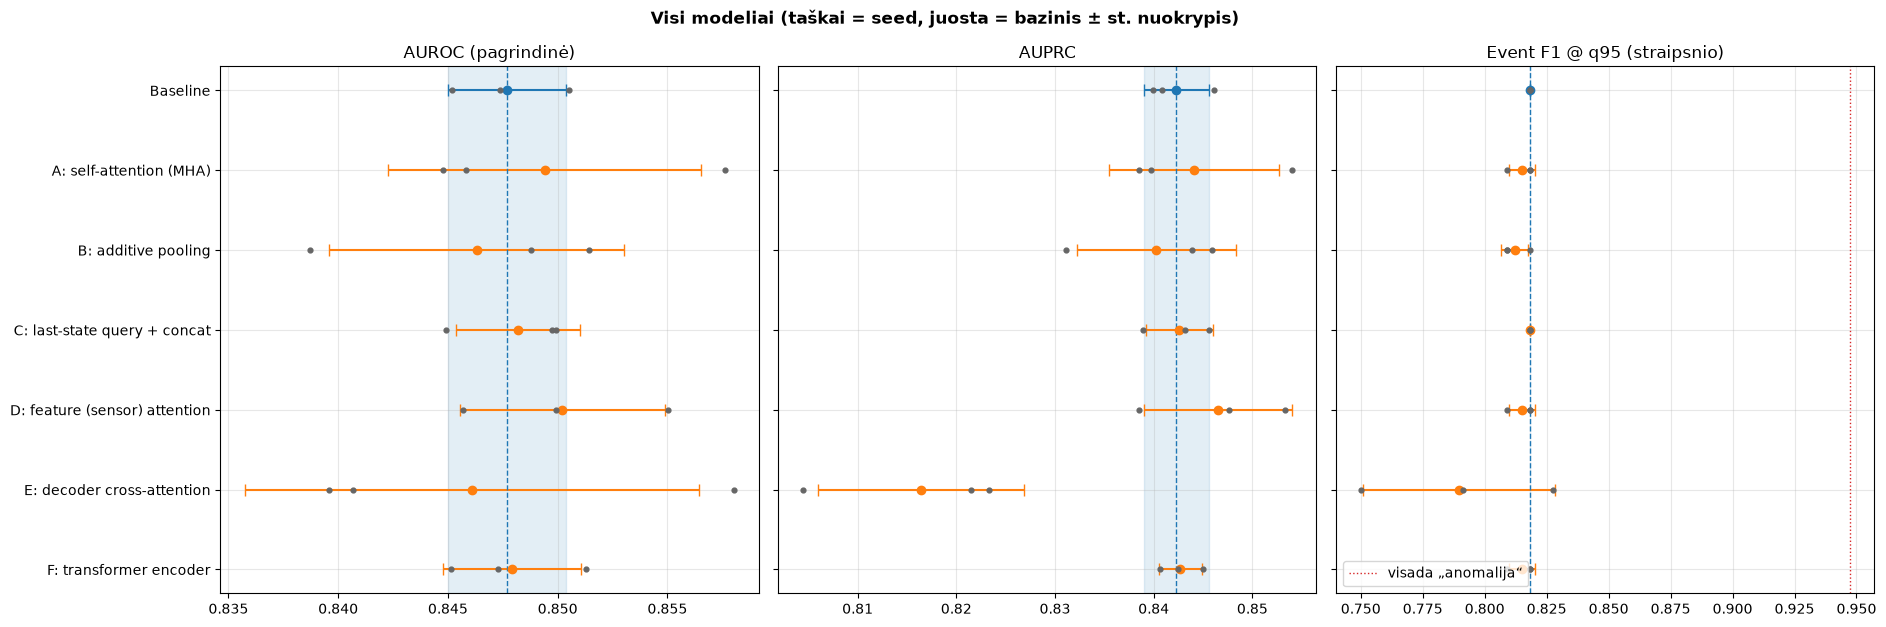

In [19]:
base = frame("Baseline")
rows = []
for name in RUNS:
    F = frame(name); seeds = [s for s in F.index if s in base.index]
    D = F.loc[seeds] - base.loc[seeds]
    rows.append({"model": name,
                 "AUROC": _ms(F.auroc, 4), "ΔAUROC": _ms(D.auroc, 4) if name != "Baseline" else "",
                 "AUPRC": _ms(F.auprc, 4), "ΔAUPRC": _ms(D.auprc, 4) if name != "Baseline" else "",
                 "F1@q95": _ms(F.f1, 3), "F1@q99": _ms(F.f1_q99, 3), "TP": _ms(F.tp, 1), "FP": _ms(F.fp, 1),
                 "pažymėta %": _ms(F.flagged_pct, 1), "mokymo MSE": _ms(F.train_loss, 5),
                 "params": int(F.params.iloc[0]), "s/mod.": _ms(F.sec, 0), "_auroc": F.auroc.mean()})
summary = pd.DataFrame(rows).sort_values("_auroc", ascending=False).drop(columns="_auroc").reset_index(drop=True)
display(summary)
p = safe_path("attention_v3_summary.csv"); summary.to_csv(p, index=False); print(f"[saved] {p}")

names = list(RUNS)
fig, ax = plt.subplots(1, 3, figsize=(19, 0.55 * len(names) + 2.5), sharey=True)
for a, key, title in zip(ax, ["auroc", "auprc", "f1"], ["AUROC (pagrindinė)", "AUPRC", "Event F1 @ q95 (straipsnio)"]):
    for i, name in enumerate(names):
        v = frame(name)[key]
        a.errorbar(v.mean(), i, xerr=v.std(ddof=1) if len(v) > 1 else 0, fmt="o", color="tab:blue" if name == "Baseline" else "tab:orange", capsize=4)
        a.scatter(v, [i] * len(v), s=12, color="0.4", zorder=3)
    b = frame("Baseline")[key]
    a.axvspan(b.mean() - (b.std(ddof=1) if len(b) > 1 else 0), b.mean() + (b.std(ddof=1) if len(b) > 1 else 0), color="tab:blue", alpha=0.12)
    a.axvline(b.mean(), color="tab:blue", ls="--", lw=1)
    if key == "f1": a.axvline(ALL_F1, color="tab:red", ls=":", lw=1, label="visada „anomalija“"); a.legend(loc="lower left")
    a.set(title=title); a.grid(alpha=0.3)
ax[0].set_yticks(range(len(names))); ax[0].set_yticklabels(names); ax[0].invert_yaxis()
fig.suptitle("Visi modeliai (taškai = seed, juosta = bazinis ± st. nuokrypis)", fontweight="bold")
plt.tight_layout(); save_fig(fig, "attention_v3_summary.png"); plt.show()